# Anti-Diabetic Medicine Sales in Australia

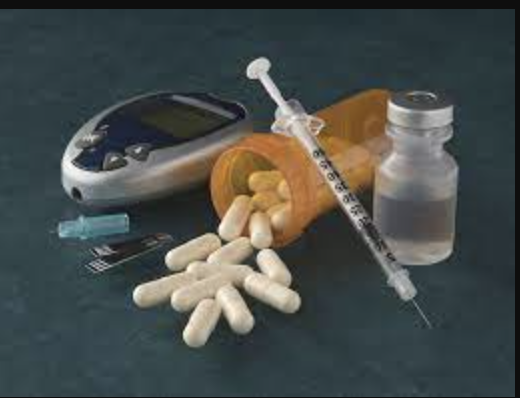

Diabetes is a chronic, long lasting health condition that affects how the human body turns food into enery. When healthy, the human body has the capacity to break down most of the food you eat into glucose and releases it into the bloodstream. When glucose or sugar marks a high level in the body, it signals the beta cells of the pancreas to release insuline, a hormone that acts like a key to allow the glucose to be used as energy source for the body's cells. 

With diabetes, the body does not produce suficient ammount of insuline resulting into to much sugar in the bloodstream. Overtime, this can cause other types of problems such as heart disease, vision loss and kidney disease. The number of people with diabetes rose from 108 million in 1980 to 422 million in 2014. Between 2000 and 2019, there was a 3% increase in diabetes mortality rates by age. 
[Centers for Disease Control and Prevention](https://www.cdc.gov/)

According to [Fortune Business Insights](https://www.fortunebusinessinsights.com/industry-reports/diabetes-drugs-market-100570) The Global Diabetes Drugs Market size was valued at USD 48.7M in 2018 and it is projected to reach USD 78.2M by the end of 2026

The most profitable companies forcasted between 2020 and 2024 

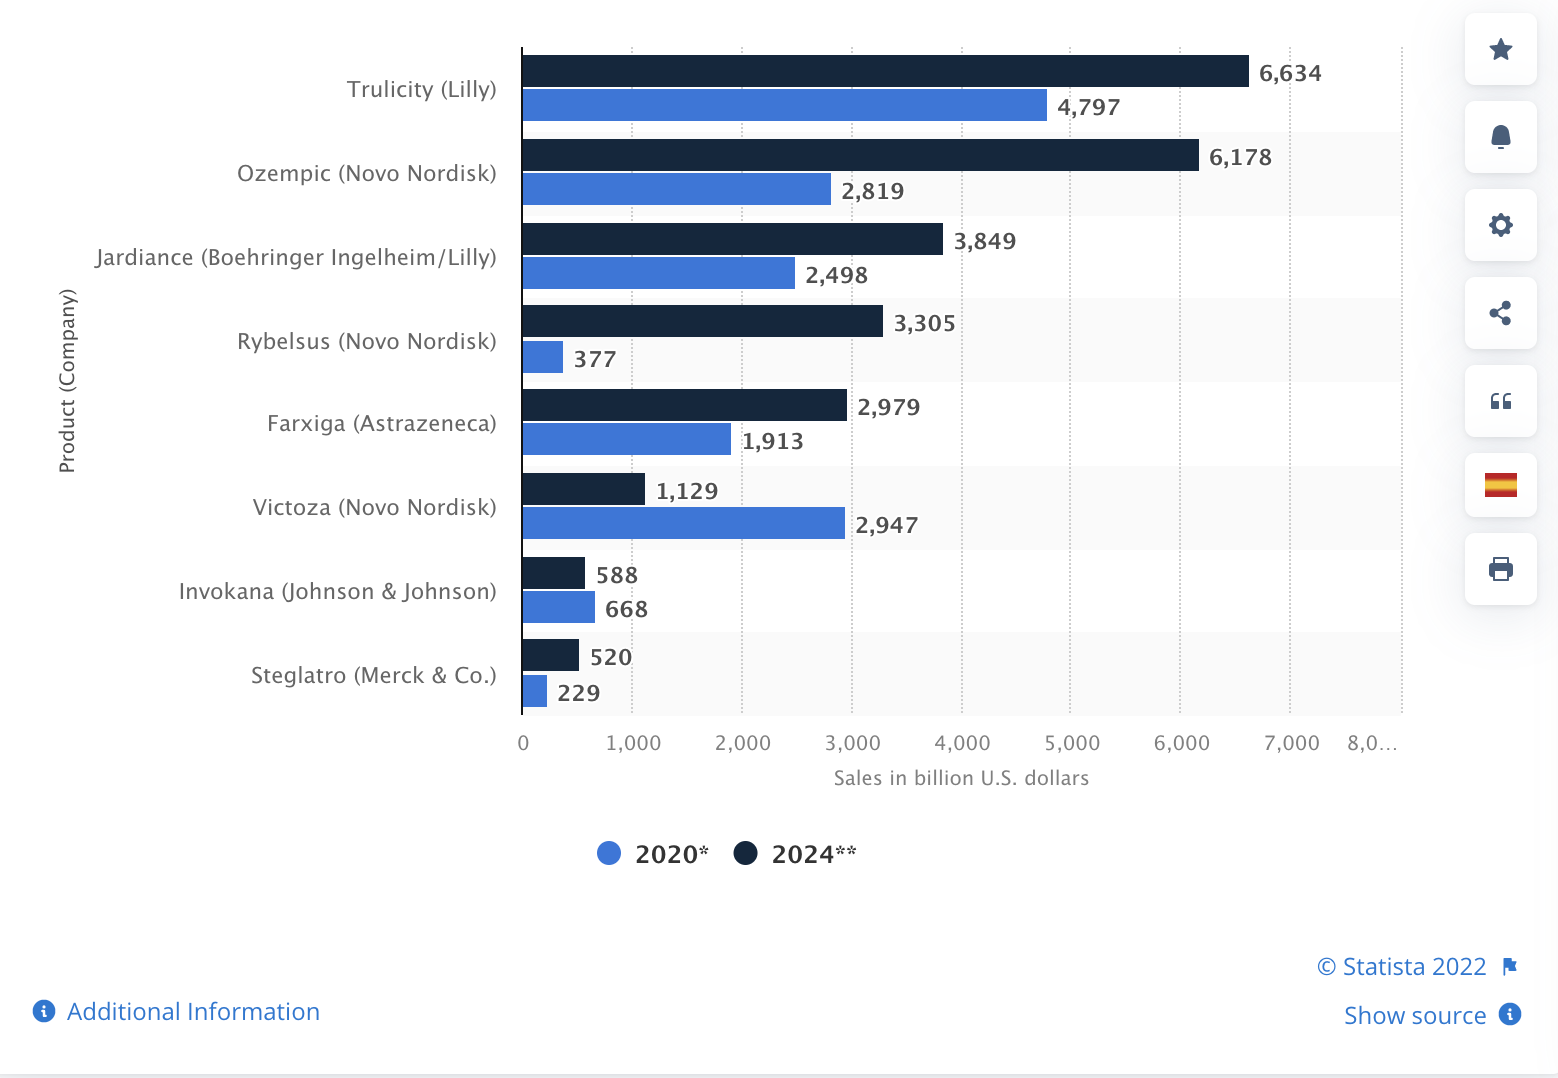


## Problem Statement

To predict and back test monthly anti-diabetic drug sales in Australia through Time series cross validation

## Import data and Libraries

In [1]:
#!pip install pmdarima


In [2]:
import matplotlib.pyplot as plt #viz #GUI manager
import seaborn as sns #viz #plotly is another package
import datetime 
import pandas as pd
import numpy as np
from pandas import Grouper #groupby
#statistical data exploration, conducting statistical tests, and estimation of different statistical models
import statsmodels.api as sm 
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf #autocorrelation plot
from statsmodels.tsa.api import SimpleExpSmoothing
from statsmodels.tsa.holtwinters import ExponentialSmoothing # double and triple exponential smoothing
from statsmodels.tsa.seasonal import seasonal_decompose
from pandas.plotting import autocorrelation_plot #autocorrelation plot
from statsmodels.graphics.gofplots import qqplot #residual diagnostics
from sklearn.metrics import mean_squared_error #accuracy metrics
from math import sqrt
from sklearn.metrics import mean_absolute_error #accuracy metrics

from random import gauss #create gaussian white noise
from random import seed
from pandas import Series 

from statsmodels.tsa.stattools import adfuller # Augmented Dickey Fuller test for testing stationarity

from statsmodels.tsa.arima_model import ARIMA #for manual ARIMA

import pmdarima as pm #auto arima
import warnings
warnings.filterwarnings("ignore")


<frozen importlib._bootstrap>:228: RuntimeWarning: scipy._lib.messagestream.MessageStream size changed, may indicate binary incompatibility. Expected 56 from C header, got 64 from PyObject


In [3]:
dmed = pd.read_csv('drug_sales_australia.csv', parse_dates=['date'], index_col=['date'])
dmed.head()


,value
date,
1991-07-01,3.526591
1991-08-01,3.180891
1991-09-01,3.252221
1991-10-01,3.611003
1991-11-01,3.565869


## Data Analysis

In [4]:
dmed.info()


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 204 entries, 1991-07-01 to 2008-06-01
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   value   204 non-null    float64
dtypes: float64(1)
memory usage: 3.2 KB


In [5]:
dmed.describe()

,value
count,204.000000
mean,10.694430
std,5.956998
min,2.814520
25%,5.844095
50%,9.319345
75%,14.289964
max,29.665356


In [6]:
## checking for missing values
dmed.isnull().sum()

value    0
dtype: int64

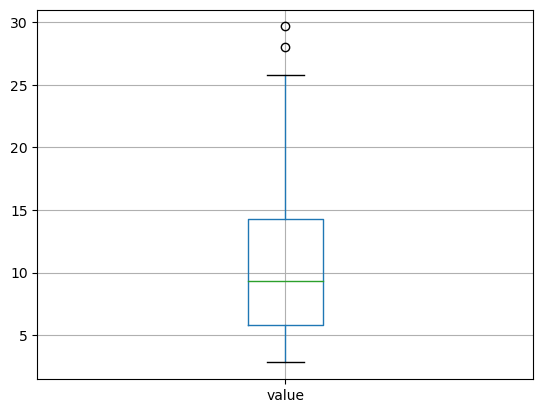

In [7]:
# Boxplot of values
dmed.boxplot()
plt.show()

In [8]:
# Find the indexes that are missing
pd.date_range(start = dmed.index.min(), end = dmed.index.max(), freq='MS').difference(dmed.index)

DatetimeIndex([], dtype='datetime64[ns]', freq='MS')

No missing indexes

### Visualizing the Series

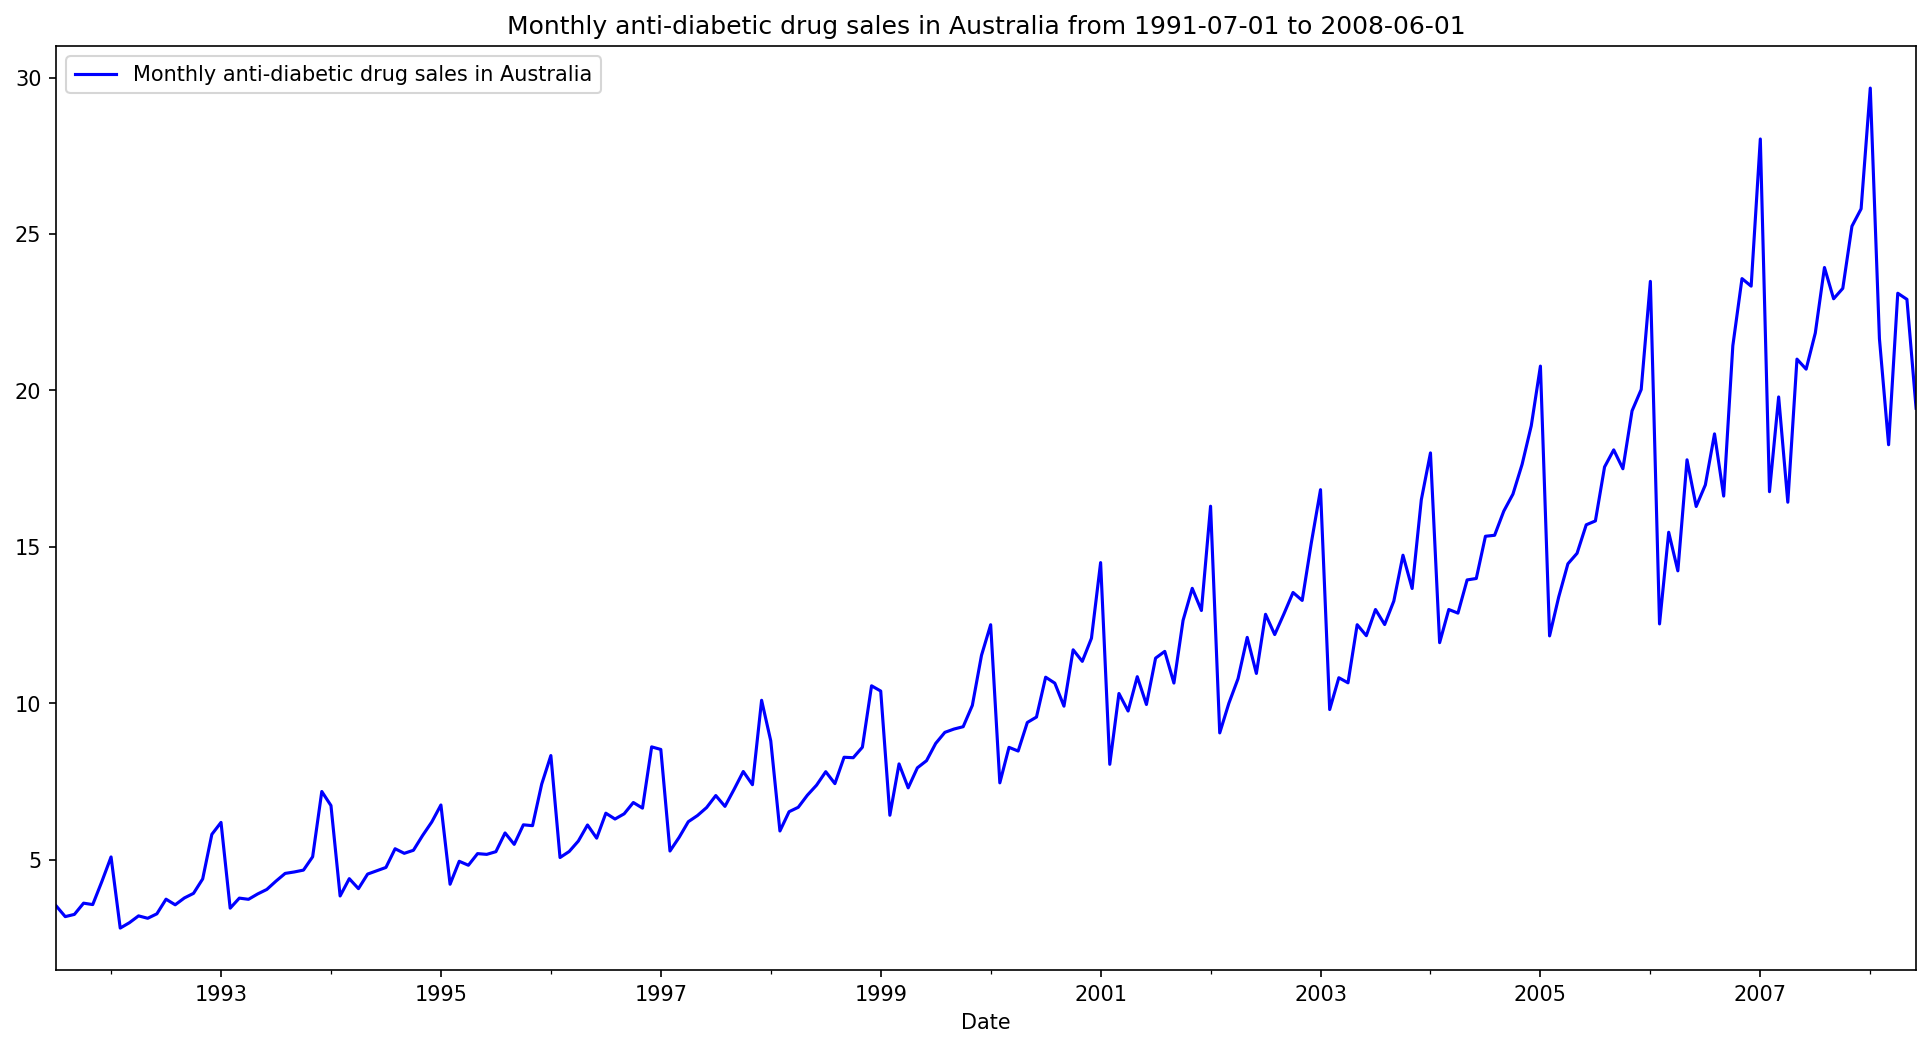

In [9]:
# to set the plot size
plt.figure(figsize=(16, 8), dpi=150) #dpi = resolution. default 100.
  
# in plot method we set the label and color of the curve.
dmed['value'].plot(label='Monthly anti-diabetic drug sales in Australia', color='blue')
  
# adding title to the plot
plt.title('Monthly anti-diabetic drug sales in Australia from {} to {}'.format('1991-07-01', '2008-06-01'))
  
# adding Label to the x-axis
plt.xlabel('Date')
  
# adding legend to the curve
plt.legend()

plt.show();

### Check if Data is Stationary or non-stationary 

To accomplish this we will check autocorrelation and seasonality

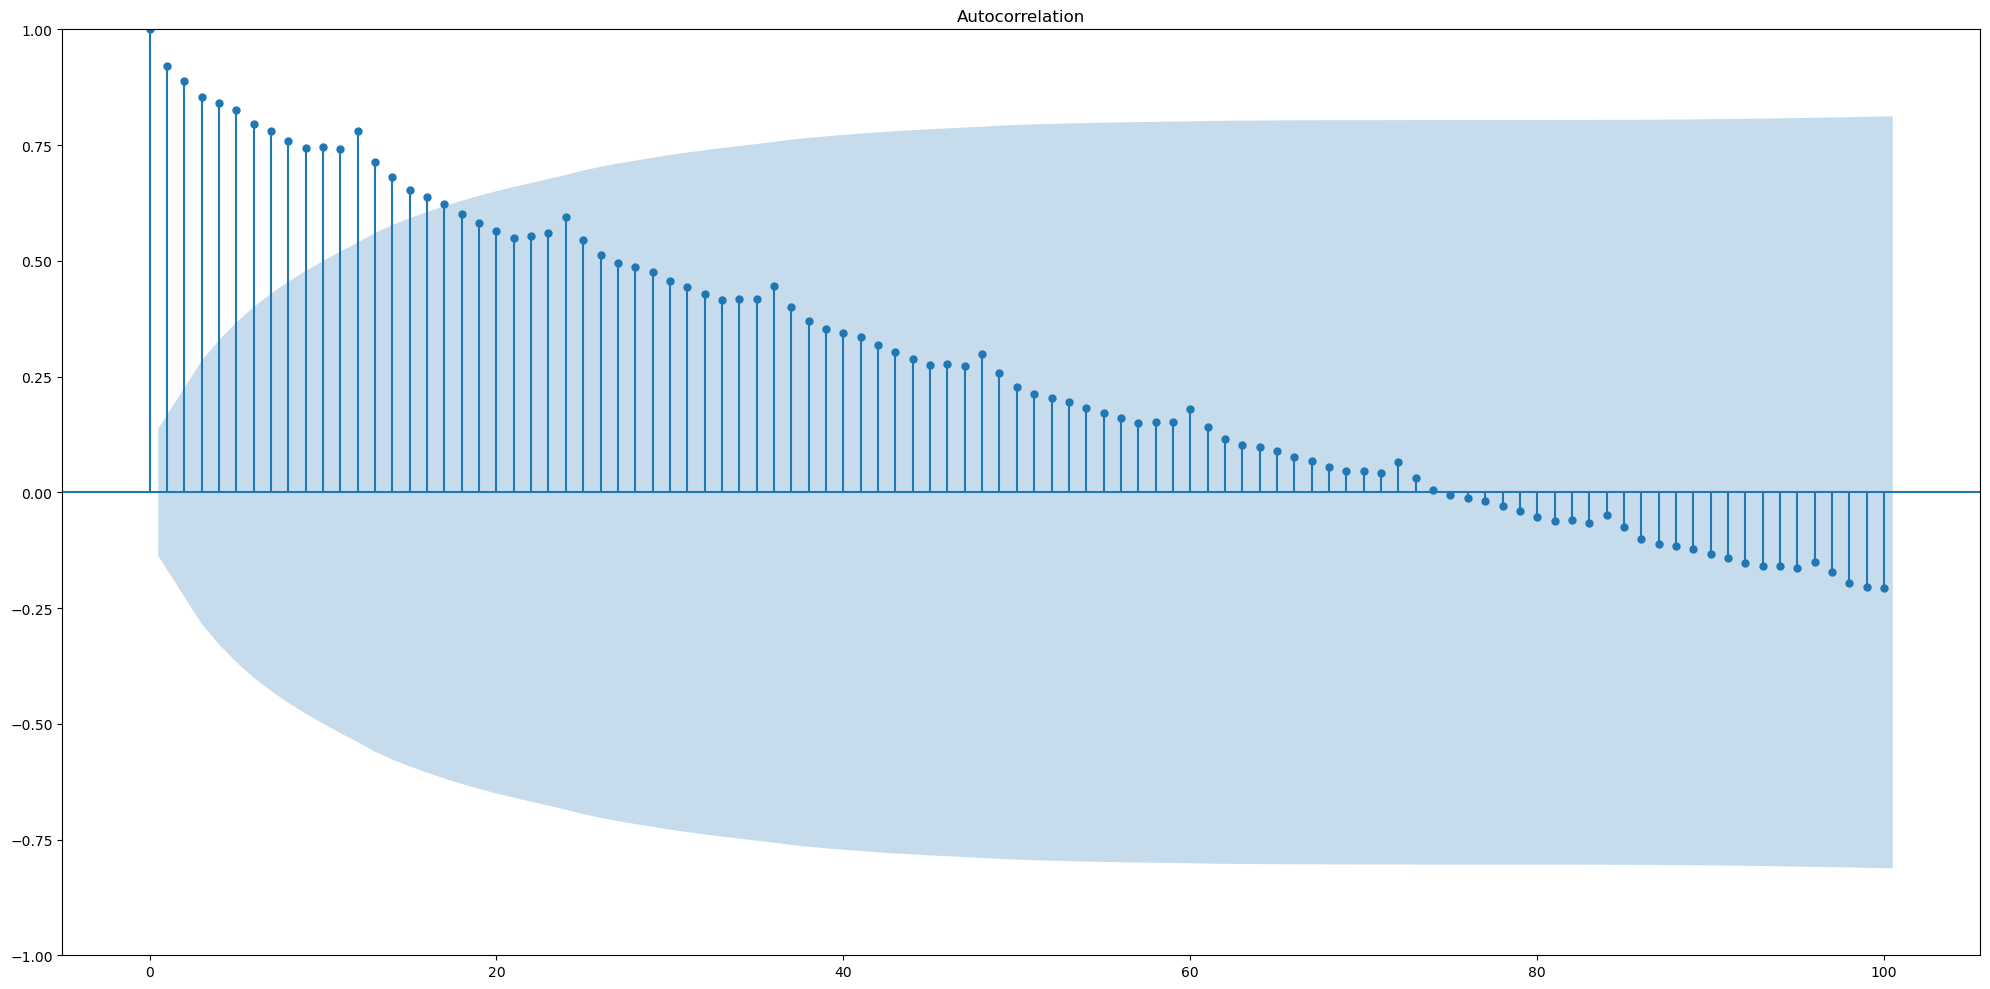

In [10]:
# autocorrelation plot of the dataset
fig = plot_acf(dmed, lags=100)
fig.set_size_inches((20, 10))
# Tight layout to realign things
fig.tight_layout()
plt.show()

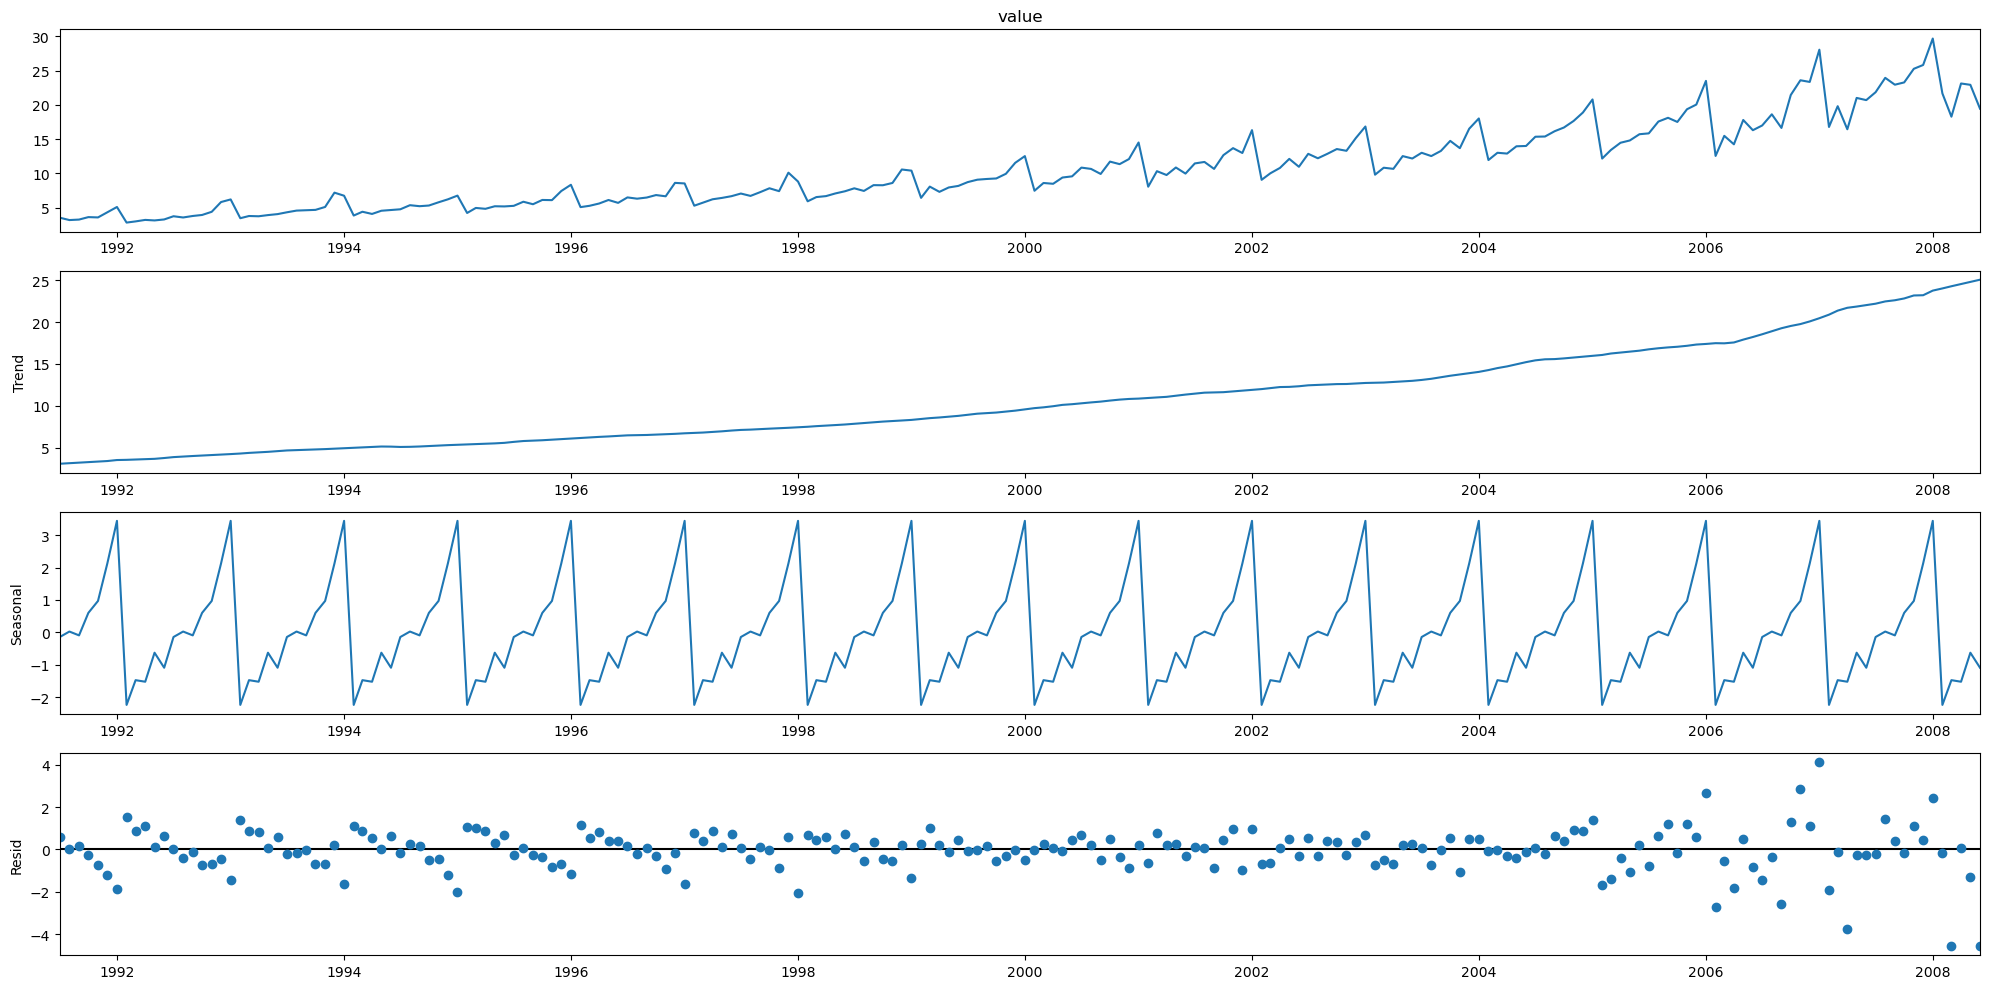

In [11]:
r = sm.tsa.seasonal_decompose(dmed['value'], extrapolate_trend='freq')
fig = r.plot()
fig.set_size_inches((20, 10))
# Tight layout to realign things
fig.tight_layout()
plt.show()

With the above graphs we can see that data has an upward trend meaning that the data has seasonality and it is non-stationary

### Transforming data into Stationary

#### Check stationarity  

In [12]:
X = dmed.values
result = adfuller(X)
print('ADF Statistic: %f' % result[0]) 
print('p-value: %f' % result[1]) 
print('Critical Values:')
for key, value in result[4].items():
    print('\t%s: %.3f' % (key, value))

ADF Statistic: 3.145186
p-value: 1.000000
Critical Values:
	1%: -3.466
	5%: -2.877
	10%: -2.575


Because p-value is greater than 0.05, is clear that we need  to reject the null hypothesis and the series is non-stationary

#### Differencing

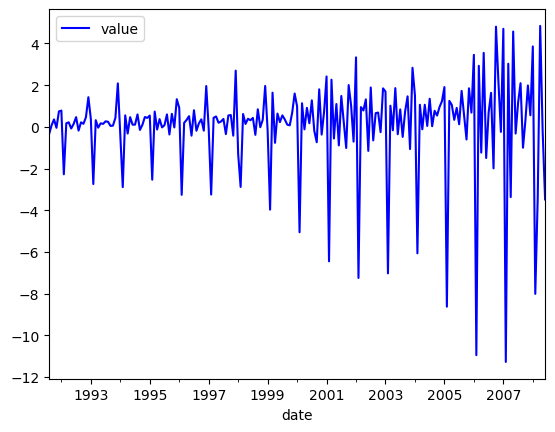

In [13]:
#create differenced dataset
first_diff_df = dmed.diff().dropna()
first_diff_df.plot(color='blue')
plt.show();

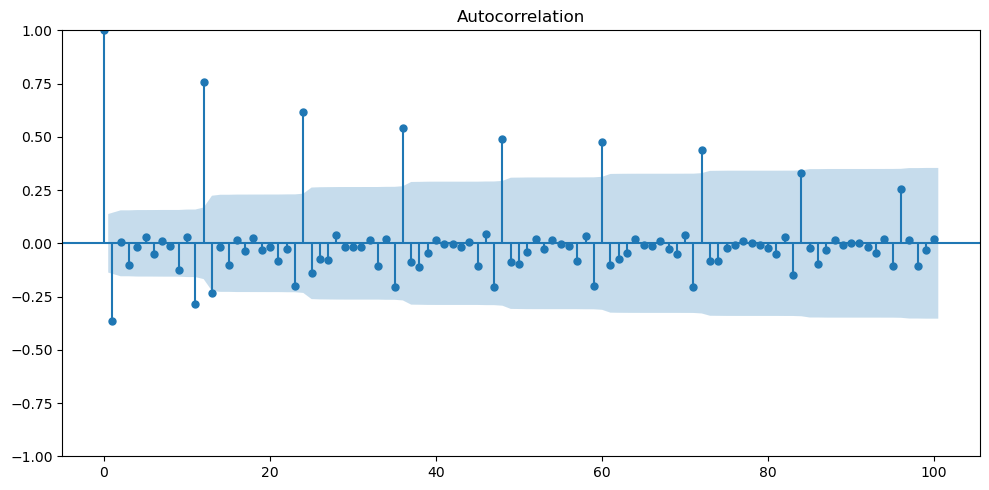

In [14]:
# autocorrelation plot of differenced dataset
fig = plot_acf(first_diff_df, lags=100)
fig.set_size_inches((10, 5))
# Tight layout to realign things
fig.tight_layout()
plt.show();

In [15]:
X = first_diff_df.values
result = adfuller(X)
print('ADF Statistic: %f' % result[0]) 
print('p-value: %f' % result[1]) 
print('Critical Values:')
for key, value in result[4].items():
    print('\t%s: %.3f' % (key, value))

ADF Statistic: -2.495172
p-value: 0.116653
Critical Values:
	1%: -3.466
	5%: -2.877
	10%: -2.575


The data is still non-stationary as shown by the ADF test and the autocorrelation plot. Sesonal difference should be applied

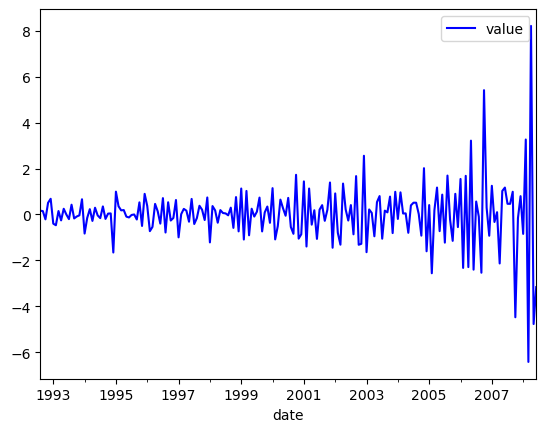

In [16]:
seasonal_diff_df = first_diff_df.diff(12).dropna()
seasonal_diff_df.plot(color = 'blue')
plt.show();

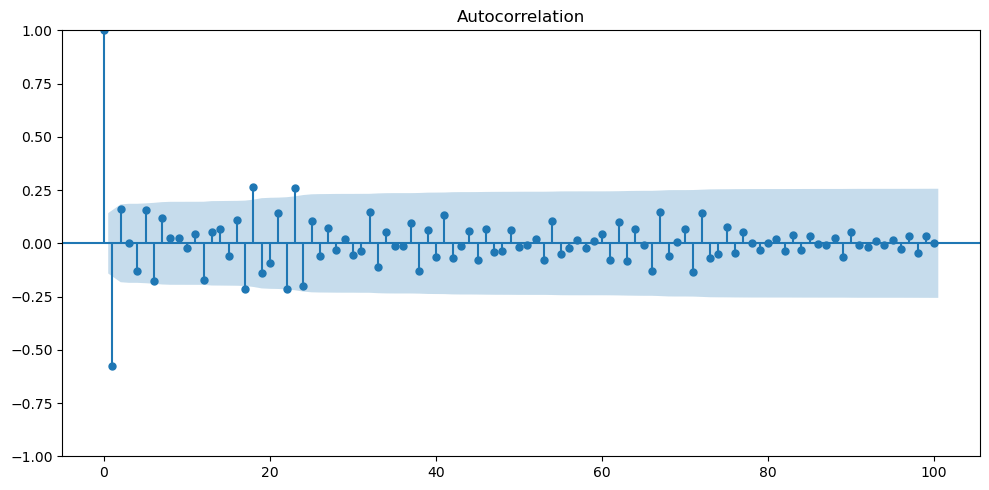

In [17]:
# autocorrelation plot of the seasonaly differenced dataset
fig = plot_acf(seasonal_diff_df, lags=100)
fig.set_size_inches((10, 5))
fig.tight_layout()
plt.show()

In [18]:
X = seasonal_diff_df.values
result = adfuller(X)
print('ADF Statistic: %f' % result[0]) 
print('p-value: %f' % result[1]) 
print('Critical Values:')
for key, value in result[4].items():
    print('\t%s: %.3f' % (key, value))

ADF Statistic: -4.783440
p-value: 0.000058
Critical Values:
	1%: -3.468
	5%: -2.878
	10%: -2.576


Since p value is less than 0.05 we can deduce that data is stationary

### Splitting data to perform forecasting

Performing back test for 4 periods 

* Part 1: July 2004-June 2005

* Part 2: July 2005-June 2006

* Part 3: July 2006-June 2007

* Part 4: July 2007-June 2008

### Part 1 July 2004-June 2005

In [19]:
# create new subset data that ends 06/2007
dmed_1 = dmed['1991-07-01' :'2005-06-01']

In [20]:
from sklearn.model_selection import train_test_split

train_data1, test_data1 = train_test_split(dmed_1, test_size=12, random_state=25, shuffle = False)
#shuffle = False is very important to ensure the order of the data

print(f"No. of training examples: {train_data1.shape[0]}")
print(f"No. of testing examples: {test_data1.shape[0]}")

No. of training examples: 156
No. of testing examples: 12


#### Plot train and test data for Period 1

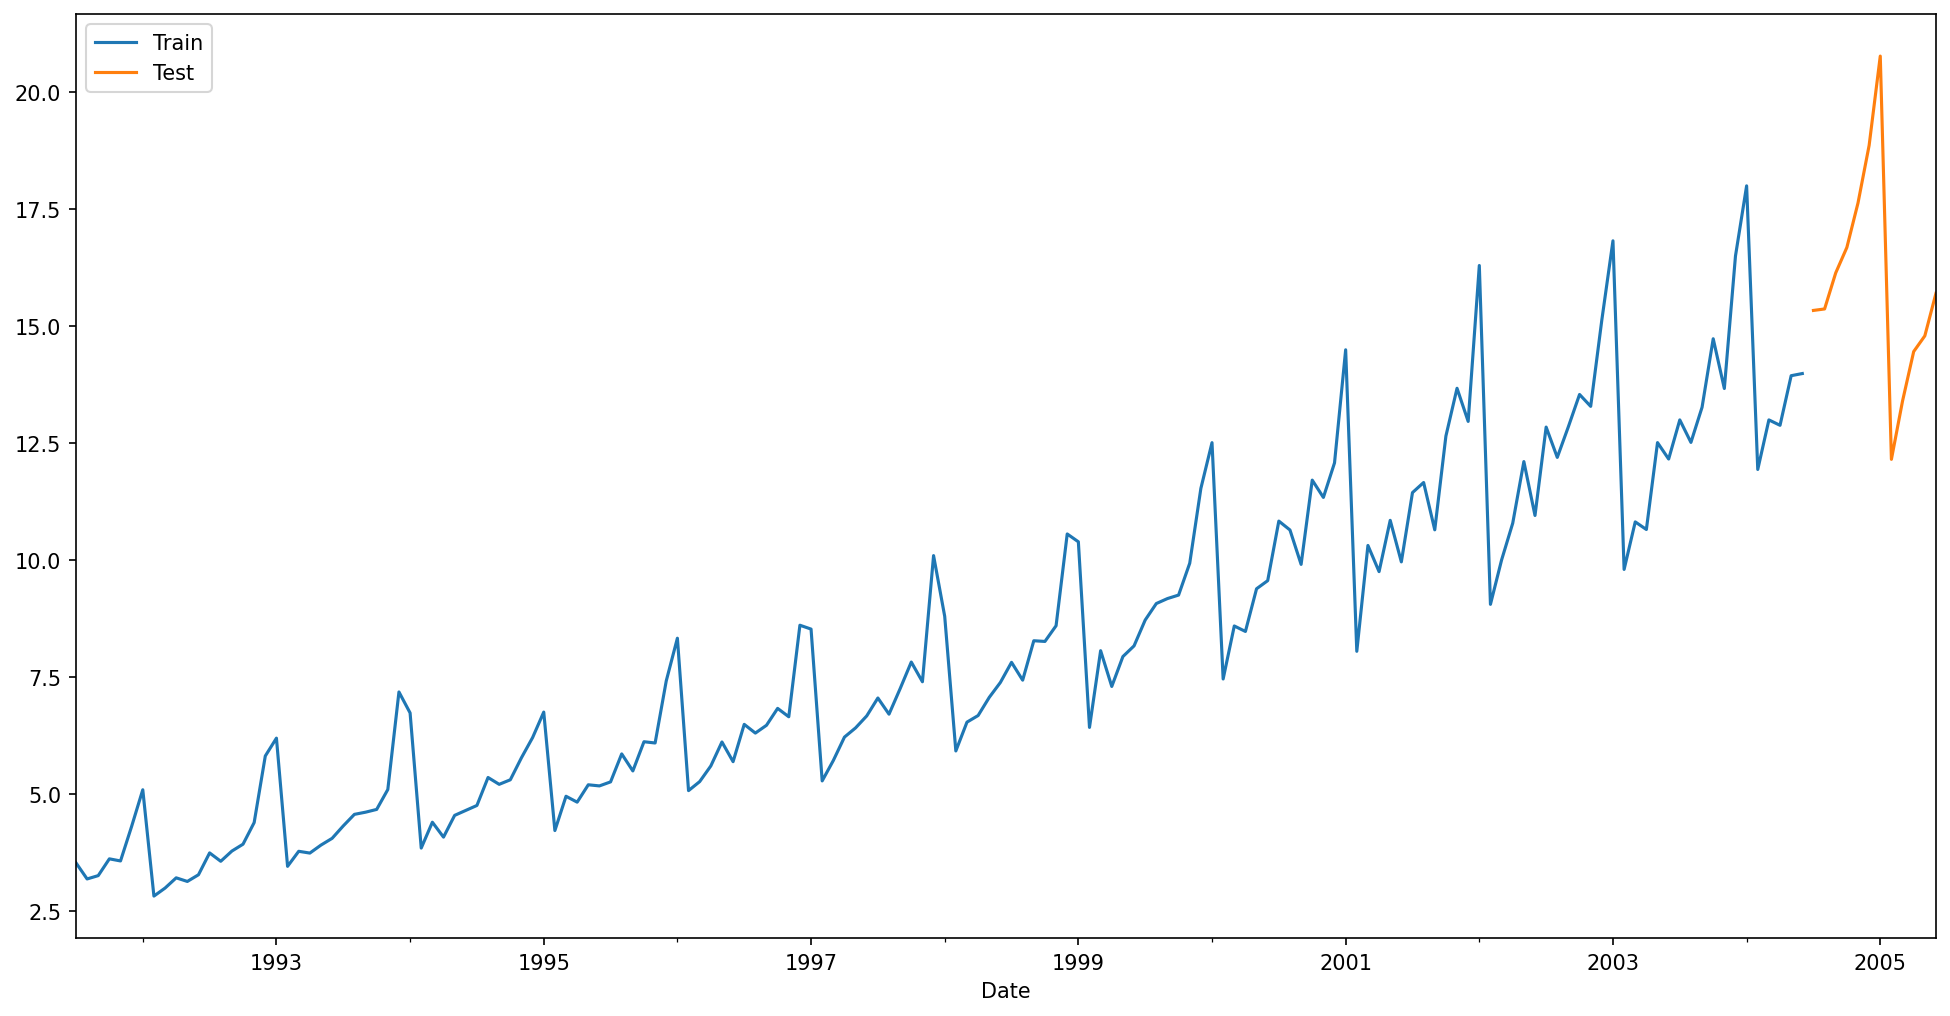

In [21]:

plt.figure(figsize=(16, 8), dpi=150)
train_data1['value'].plot(label='Train')
test_data1['value'].plot(label='Test')
plt.xlabel('Date')
plt.legend()
plt.show();

### ETS Model - Error trend and seasonality

#### Simple Exponential Smoothing

In [22]:
#First Instance
ins1 = SimpleExpSmoothing(train_data1).fit(smoothing_level=0.2,optimized=False)
ins_cast1 = ins1.forecast(12).rename('alpha=0.2')

#Second Instance
ins2 = SimpleExpSmoothing(train_data1).fit(smoothing_level=0.8,optimized=False)
ins_cast2 = ins2.forecast(12).rename('alpha=0.5')

#Third Instance
ins3 = SimpleExpSmoothing(train_data1).fit()
ins_cast3 = ins3.forecast(12).rename('alpha=%s'%ins3.model.params['smoothing_level'])

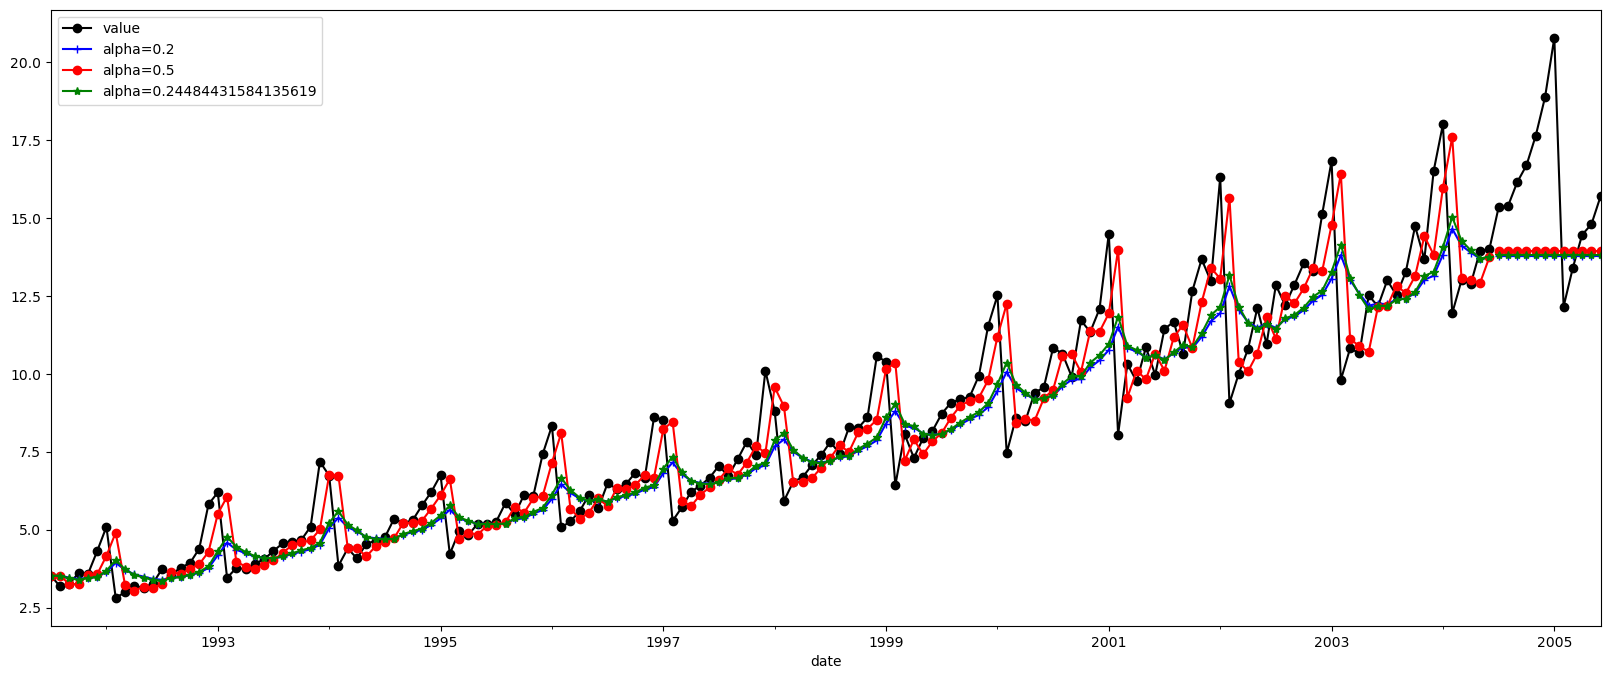

In [23]:
#After creating model we will visualize the plot
ax = dmed_1.plot(marker='o', color='black', figsize=(20,8), legend=True)

#Plot for alpha =0.2
ins_cast1.plot(marker='+', ax=ax, color='blue', legend=True)
ins1.fittedvalues.plot(marker='+', ax=ax, color='blue')

#Plot for alpha = 0.5
ins_cast2.plot(marker='o', ax=ax, color='red', legend=True)
ins2.fittedvalues.plot(marker='o', ax=ax, color='red')

#Plot for alpha=Optimized by statsmodel
ins_cast3.plot(marker='*', ax=ax, color='green', legend=True)
ins3.fittedvalues.plot(marker='*', ax=ax, color='green')

plt.show()

#### Double Exponential Smoothing 

In [24]:
double_ets_add = ExponentialSmoothing(train_data1, trend = 'add').fit()
double_ets_mul = ExponentialSmoothing(train_data1, trend = 'mul').fit()

double_ets_add_pred = double_ets_add.forecast(12)
double_ets_mul_pred = double_ets_mul.forecast(12)

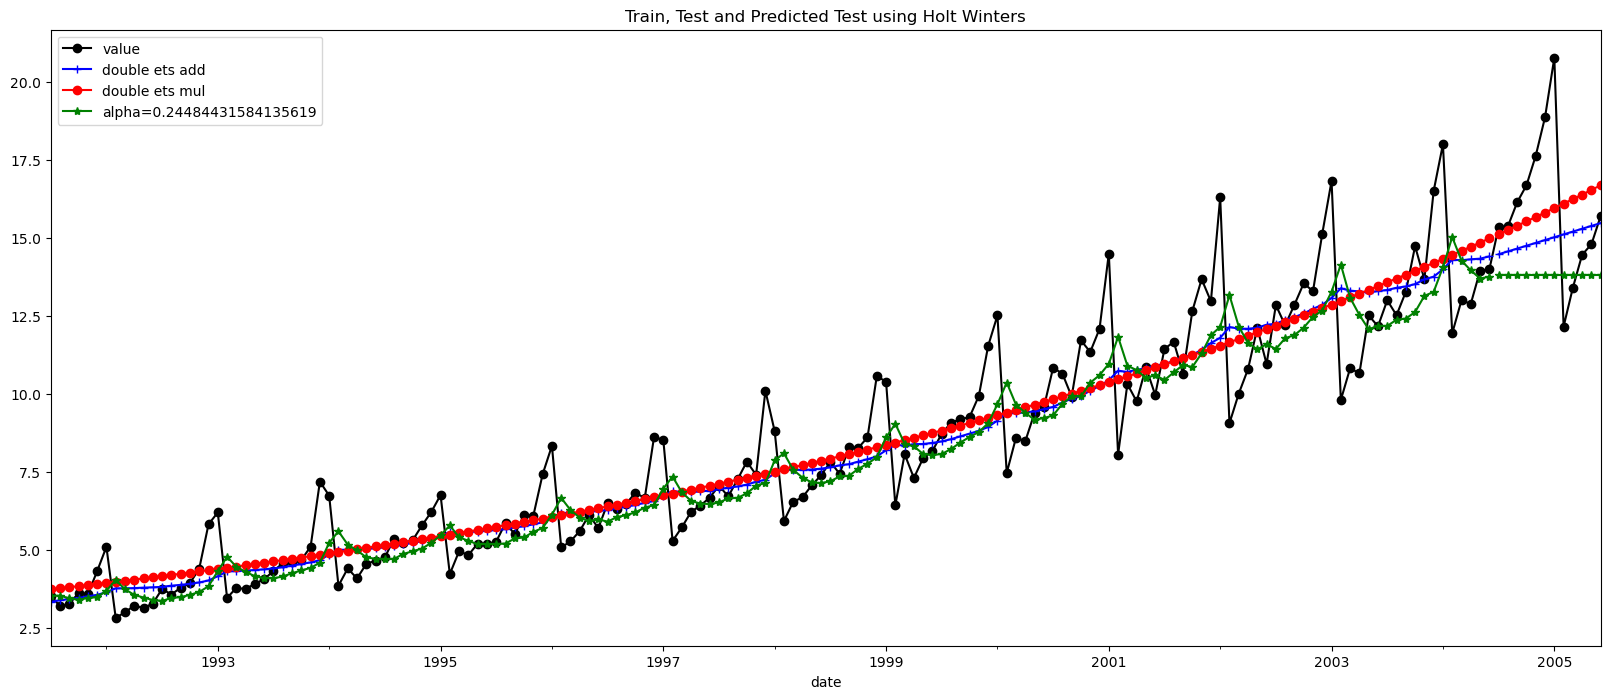

In [25]:
#plot the train, test, and predictions

#After creating model we will visualize the plot
ax = dmed_1.plot(marker='o', color='black', figsize=(20,8), legend=True)

#Plot for double ETS additive
double_ets_add_pred.plot(marker='+', ax=ax, color='blue', legend=True, label = 'double ets add')
double_ets_add.fittedvalues.plot(marker='+', ax=ax, color='blue')

#Plot for double ETS multiplicative
double_ets_mul_pred.plot(marker='o', ax=ax, color='red', legend=True, label = 'double ets mul')
double_ets_mul.fittedvalues.plot(marker='o', ax=ax, color='red')

#Plot for simple exponential smooting alpha=Optimized by statsmodel
ins_cast3.plot(marker='*', ax=ax, color='green', legend=True)
ins3.fittedvalues.plot(marker='*', ax=ax, color='green')
plt.title('Train, Test and Predicted Test using Holt Winters')
plt.show()

#### Triple Exponential Smoothing 

This is the extended version of simple exponential smoothing to allow the forecasting of data with a trend and seasonality.

In [26]:
# triple ETS - Holt Winter's Seasonal Method
triple_ets_add = ExponentialSmoothing(train_data1, trend = 'add', seasonal = 'add', seasonal_periods=12).fit()
triple_ets_mul = ExponentialSmoothing(train_data1, trend = 'mul', seasonal = 'mul', seasonal_periods=12).fit()

triple_ets_add_pred = triple_ets_add.forecast(12)
triple_ets_mul_pred = triple_ets_mul.forecast(12)

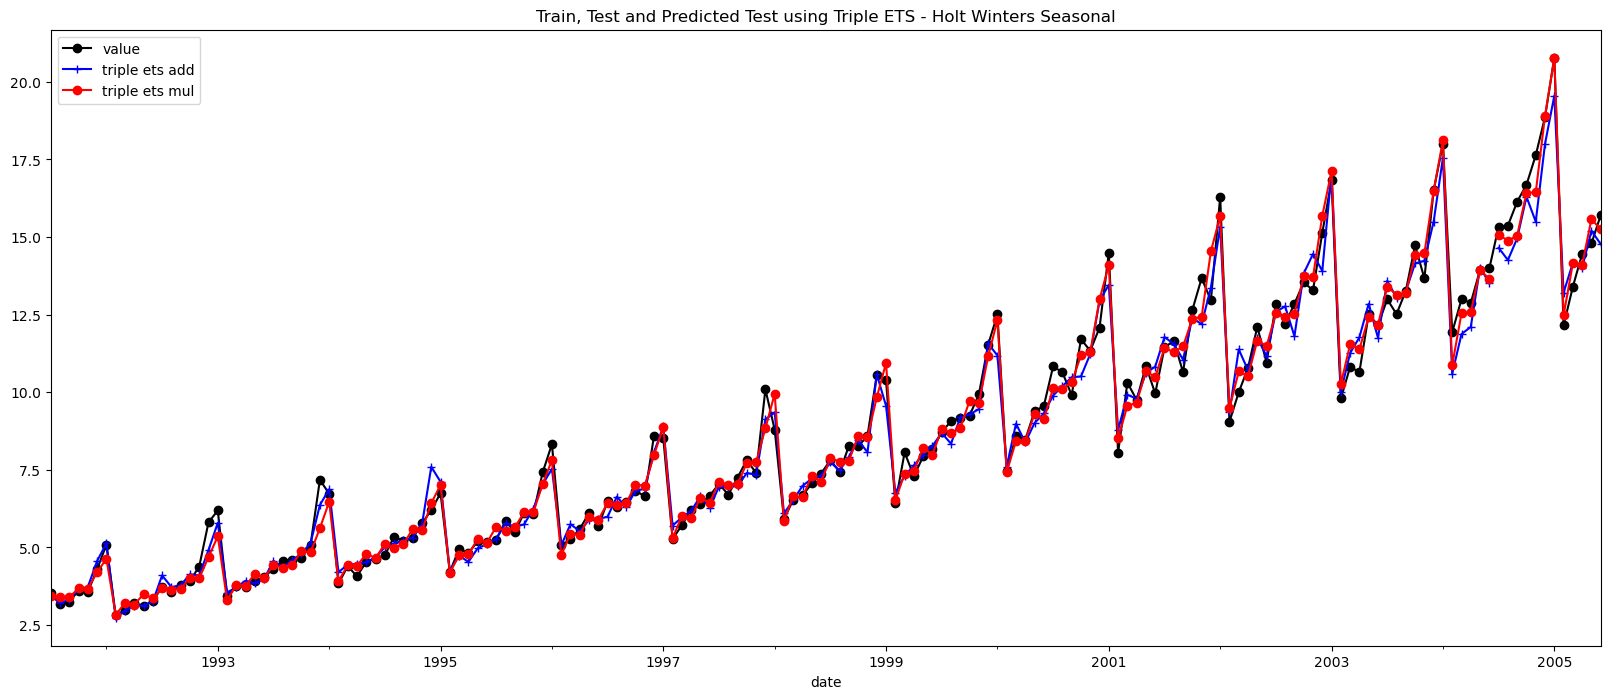

In [27]:
#plot the train, test, and predictions

#After creating model we will visualize the plot
ax = dmed_1.plot(marker='o', color='black', figsize=(20,8), legend=True)

#Plot for double ETS additive
triple_ets_add_pred.plot(marker='+', ax=ax, color='blue', legend=True, label = 'triple ets add')
triple_ets_add.fittedvalues.plot(marker='+', ax=ax, color='blue')

#Plot for double ETS multiplicative
triple_ets_mul_pred.plot(marker='o', ax=ax, color='red', legend=True, label = 'triple ets mul')
triple_ets_mul.fittedvalues.plot(marker='o', ax=ax, color='red')

plt.title('Train, Test and Predicted Test using Triple ETS - Holt Winters Seasonal')
plt.show()

#### Manual Arima

In [28]:
# p,d,q = 0,2,1 ARIMA Model
manual_model = sm.tsa.ARIMA(train_data1, order=(0,2,1))
manual_model_fit = manual_model.fit()
print(manual_model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                  value   No. Observations:                  156
Model:                 ARIMA(0, 2, 1)   Log Likelihood                -294.921
Date:                Fri, 18 Nov 2022   AIC                            593.842
Time:                        17:59:33   BIC                            599.916
Sample:                    07-01-1991   HQIC                           596.309
                         - 06-01-2004                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.9998      5.557     -0.180      0.857     -11.891       9.891
sigma2         2.6110     14.624      0.179      0.858     -26.051      31.273
Ljung-Box (L1) (Q):                  17.49   Jarque-

In [29]:
# Forecast
fc= manual_model_fit.forecast(12, alpha=0.05)  # 95% conf


In [30]:
conf= manual_model_fit.forecast(alpha=0.05)  # 95% conf


In [31]:
fc_series = pd.Series(fc, index=test_data1.index)
lower_series = pd.Series(conf, index=test_data1.index)
upper_series = pd.Series(conf, index=test_data1.index)


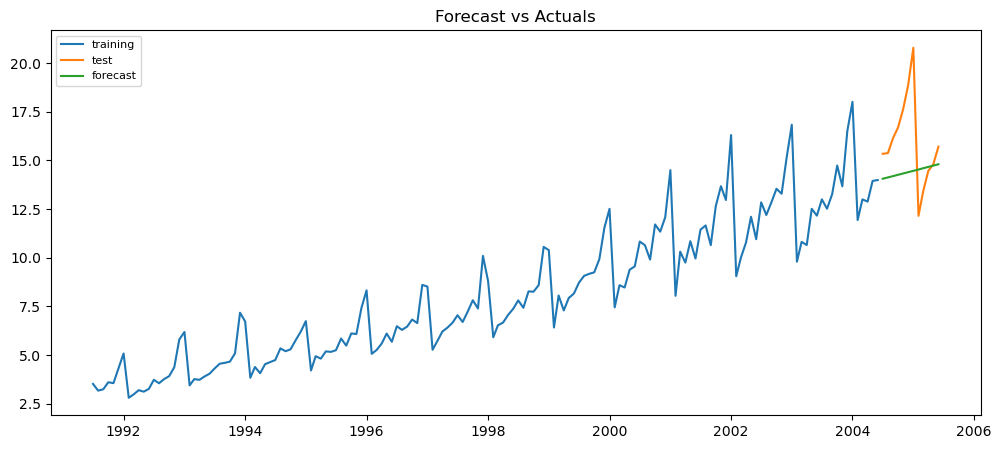

In [32]:
# Plot
plt.figure(figsize=(12,5), dpi=100)
plt.plot(train_data1, label='training')
plt.plot(test_data1, label='test')
plt.plot(fc_series, label='forecast')
plt.fill_between(lower_series.index, lower_series, upper_series, 
                 color='k', alpha=.15)
plt.title('Forecast vs Actuals')
plt.legend(loc='upper left', fontsize=8)
plt.show();


#### Auto ARIMA - Non Seasonal

In [33]:
non_seasonal_auto_model = pm.auto_arima(train_data1, start_p=0, start_q=0, 
                          test='adf',       # use adftest to find optimal 'd'
                          max_p=3, max_q=3, # maximum p and q
                          m=12,              # frequency of series
                          d=None,           # let model determine 'd'
                          seasonal=False,   # No Seasonality
                          trace=True,
                          error_action='ignore',  
                          suppress_warnings=True, 
                          stepwise=True)

print(non_seasonal_auto_model.summary())

Performing stepwise search to minimize aic
 ARIMA(0,0,0)(0,0,0)[0]             : AIC=1123.692, Time=0.02 sec
 ARIMA(1,0,0)(0,0,0)[0]             : AIC=598.075, Time=0.04 sec
 ARIMA(0,0,1)(0,0,0)[0]             : AIC=961.453, Time=0.04 sec
 ARIMA(2,0,0)(0,0,0)[0]             : AIC=inf, Time=0.05 sec
 ARIMA(1,0,1)(0,0,0)[0]             : AIC=565.571, Time=0.06 sec
 ARIMA(2,0,1)(0,0,0)[0]             : AIC=558.166, Time=0.10 sec
 ARIMA(3,0,1)(0,0,0)[0]             : AIC=560.084, Time=0.13 sec
 ARIMA(2,0,2)(0,0,0)[0]             : AIC=566.735, Time=0.15 sec
 ARIMA(1,0,2)(0,0,0)[0]             : AIC=558.602, Time=0.09 sec
 ARIMA(3,0,0)(0,0,0)[0]             : AIC=inf, Time=0.06 sec
 ARIMA(3,0,2)(0,0,0)[0]             : AIC=578.426, Time=0.31 sec
 ARIMA(2,0,1)(0,0,0)[0] intercept   : AIC=558.613, Time=0.16 sec

Best model:  ARIMA(2,0,1)(0,0,0)[0]          
Total fit time: 1.237 seconds
                               SARIMAX Results                                
Dep. Variable:              

In [34]:
# Forecast
n_periods = 12
fc_auto_nonseasonal, confint = non_seasonal_auto_model.predict(n_periods=n_periods, return_conf_int=True)

In [35]:
fc_auto_nonseasonal

2004-07-01    13.779698
2004-08-01    13.715521
2004-09-01    13.692685
2004-10-01    13.681589
2004-11-01    13.673829
2004-12-01    13.667018
2005-01-01    13.660479
2005-02-01    13.654019
2005-03-01    13.647584
2005-04-01    13.641158
2005-05-01    13.634737
2005-06-01    13.628319
Freq: MS, dtype: float64

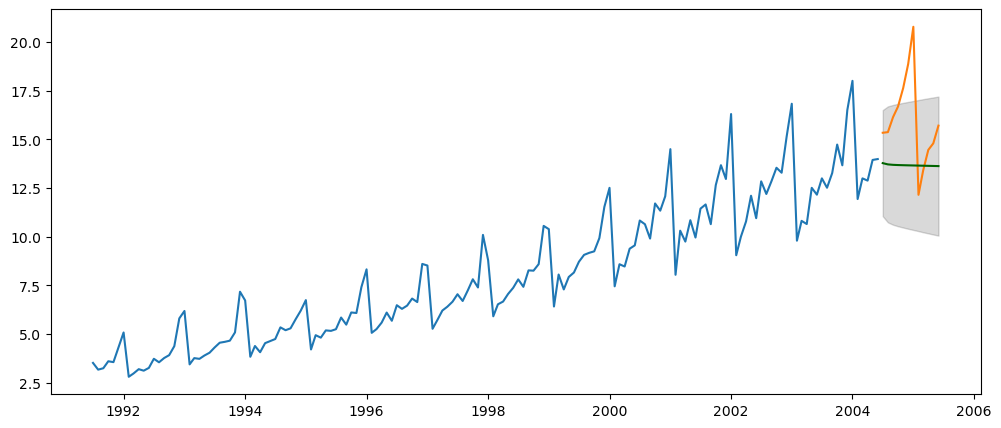

In [36]:
# make plot
fc_series_auto_nonseasonal = pd.Series(fc_auto_nonseasonal, index=test_data1.index)
lower_series = pd.Series(confint[:, 0], index=test_data1.index)
upper_series = pd.Series(confint[:, 1], index=test_data1.index)

# Plot
plt.figure(figsize=(12,5), dpi=100)
plt.plot(train_data1, label='train')
plt.plot(test_data1, label='test')
plt.plot(fc_series_auto_nonseasonal, color='darkgreen', label='forecast')
plt.fill_between(lower_series.index, 
                 lower_series, 
                 upper_series, 
                 color='k', alpha=.15)

plt.show()

#### Auto ARIMA Seasonal 

In [37]:
# Seasonal - fit stepwise auto-ARIMA
smodel = pm.auto_arima(train_data1, start_p=1, start_q=1,
                         test='adf',
                         max_p=3, max_q=3, m=12,
                         start_P=0, seasonal=True,
                         d=None, D=1, trace=True,
                         error_action='ignore',  
                         suppress_warnings=True, 
                         stepwise=True)

smodel.summary()

Performing stepwise search to minimize aic
 ARIMA(1,1,1)(0,1,1)[12]             : AIC=226.709, Time=0.23 sec
 ARIMA(0,1,0)(0,1,0)[12]             : AIC=310.796, Time=0.03 sec
 ARIMA(1,1,0)(1,1,0)[12]             : AIC=260.993, Time=0.08 sec
 ARIMA(0,1,1)(0,1,1)[12]             : AIC=227.309, Time=0.12 sec
 ARIMA(1,1,1)(0,1,0)[12]             : AIC=229.668, Time=0.06 sec
 ARIMA(1,1,1)(1,1,1)[12]             : AIC=225.508, Time=0.37 sec
 ARIMA(1,1,1)(1,1,0)[12]             : AIC=228.659, Time=0.14 sec
 ARIMA(1,1,1)(2,1,1)[12]             : AIC=225.817, Time=0.57 sec
 ARIMA(1,1,1)(1,1,2)[12]             : AIC=226.347, Time=0.90 sec
 ARIMA(1,1,1)(0,1,2)[12]             : AIC=224.365, Time=0.53 sec
 ARIMA(0,1,1)(0,1,2)[12]             : AIC=224.161, Time=0.41 sec
 ARIMA(0,1,1)(1,1,2)[12]             : AIC=225.964, Time=0.63 sec
 ARIMA(0,1,1)(1,1,1)[12]             : AIC=225.121, Time=0.29 sec
 ARIMA(0,1,0)(0,1,2)[12]             : AIC=306.412, Time=0.25 sec
 ARIMA(0,1,2)(0,1,2)[12]         

<class 'statsmodels.iolib.summary.Summary'>
"""
                                        SARIMAX Results                                        
===============================================================================================
Dep. Variable:                                       y   No. Observations:                  156
Model:             SARIMAX(0, 1, 1)x(0, 1, [1, 2], 12)   Log Likelihood                -108.080
Date:                                 Fri, 18 Nov 2022   AIC                            224.161
Time:                                         17:59:48   BIC                            236.012
Sample:                                     07-01-1991   HQIC                           228.977
                                          - 06-01-2004                                         
Covariance Type:                                   opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.8324      0.052    -15.965      0.000      -0.935      -0.730
ma.S.L12      -0.2090      0.074     -2.810      0.005      -0.355      -0.063
ma.S.L24      -0.1888      0.088     -2.151      0.032      -0.361      -0.017
sigma2         0.2601      0.027      9.514      0.000       0.207       0.314
===================================================================================
Ljung-Box (L1) (Q):                   1.26   Jarque-Bera (JB):                 2.77
Prob(Q):                              0.26   Prob(JB):                         0.25
Heteroskedasticity (H):               3.70   Skew:                            -0.01
Prob(H) (two-sided):                  0.00   Kurtosis:                         3.68
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [38]:
# Forecast
n_periods = 12
fc_auto_seasonal, confint = smodel.predict(n_periods=n_periods, return_conf_int=True)

In [39]:
fc_auto_seasonal

2004-07-01    14.511725
2004-08-01    14.178494
2004-09-01    14.609967
2004-10-01    16.099150
2004-11-01    15.424339
2004-12-01    17.652308
2005-01-01    19.364361
2005-02-01    13.253867
2005-03-01    14.329013
2005-04-01    14.331786
2005-05-01    15.389397
2005-06-01    15.255914
Freq: MS, dtype: float64

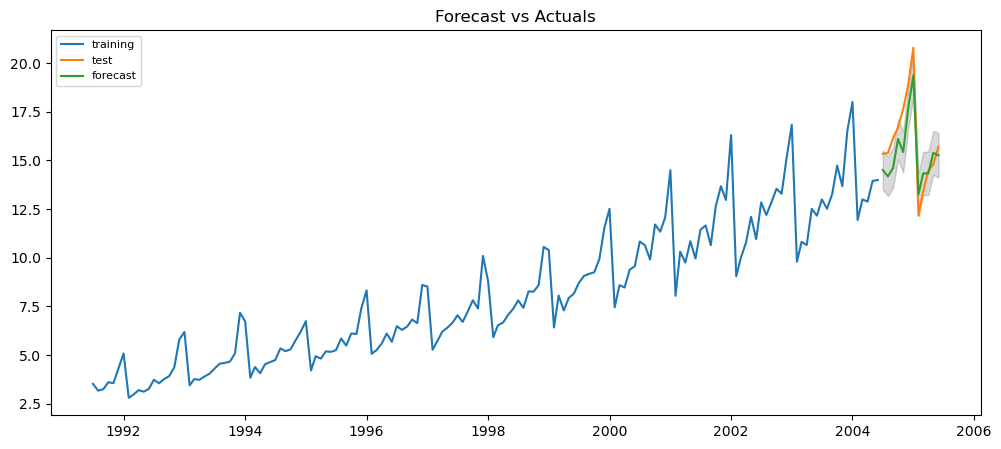

In [40]:
# make series for plotting purpose
fc_series_auto_seasonal = pd.Series(fc_auto_seasonal, index=test_data1.index)
lower_series = pd.Series(confint[:, 0], index=test_data1.index)
upper_series = pd.Series(confint[:, 1], index=test_data1.index)

# Plot
plt.figure(figsize=(12,5), dpi=100)
plt.plot(train_data1, label='training')
plt.plot(test_data1, label='test')
plt.plot(fc_series_auto_seasonal, label='forecast')
plt.fill_between(lower_series.index, lower_series, upper_series, 
                 color='k', alpha=.15)
plt.title('Forecast vs Actuals')
plt.legend(loc='upper left', fontsize=8)
plt.show()

#### Model Evaluation

In [41]:
#define metrics dataframe which will be used below for 
metrics_dataframe = pd.DataFrame(columns=['Model', 'RMSE', 'MAE', 'MAPE'])

                                 
def metrics_cal(actuals, predictions, model):
    mse = mean_squared_error(actuals, predictions)
    rmse = sqrt(mse)
    mae = mean_absolute_error(actuals, predictions)
    mape = np.mean(np.abs((actuals - predictions) / actuals)) * 100
    
    df = pd.DataFrame({'Model': model,
                       'RMSE': rmse,
                       'MAE': mae, 
                       'MAPE': mape}, index=[0])
    dataframe = metrics_dataframe.append(df)
    return dataframe

In [42]:
#get all the metrics

metrics_dataframe = metrics_cal(test_data1.values.flatten(), 
                                triple_ets_add_pred.values.flatten(), 
                                'Triple Add')

metrics_dataframe = metrics_cal(test_data1.values.flatten(), 
                                triple_ets_mul_pred.values.flatten(), 
                                'Triple Mul')

metrics_dataframe = metrics_cal(test_data1.values.flatten(), 
                                fc_series.values.flatten(), 
                                'Manual ARIMA')

metrics_dataframe = metrics_cal(test_data1.values.flatten(), 
                                fc_series_auto_nonseasonal.values.flatten(), 
                                'Auto ARIMA Non Seasonal')

metrics_dataframe = metrics_cal(test_data1.values.flatten(), 
                                fc_series_auto_seasonal.values.flatten(), 
                                'Auto ARIMA Seasonal')

In [43]:
metrics_dataframe.sort_values(by='MAE')

,Model,RMSE,MAE,MAPE
0,Triple Mul,0.620156,0.500351,3.258820
0,Triple Add,1.041147,0.933409,5.843408
0,Auto ARIMA Seasonal,1.147895,1.014923,6.306299
0,Manual ARIMA,2.764353,2.145802,12.669592
0,Auto ARIMA Non Seasonal,3.192067,2.562634,14.941777


In [44]:
# Create a data frame with all the predictions along with the test data
test_pred_df = test_data1.copy()

# Add all predictions 
test_pred_df = test_pred_df.assign(manual_arima_pred = fc_series.values.flatten(),
                                   auto_nonseasonal_pred = fc_series_auto_nonseasonal.values.flatten(),
                                   auto_seasonal_pred = fc_series_auto_seasonal.values.flatten(),
                                   avg_pred = (fc_series.values.flatten()+
                                               fc_series_auto_nonseasonal.values.flatten()+
                                               fc_series_auto_seasonal.values.flatten())/3)

test_pred_df

,value,manual_arima_pred,auto_nonseasonal_pred,auto_seasonal_pred,avg_pred
date,,,,,
2004-07-01,15.339097,14.056976,13.779698,14.511725,14.116133
2004-08-01,15.370764,14.124481,13.715521,14.178494,14.006165
2004-09-01,16.142005,14.191985,13.692685,14.609967,14.164879
2004-10-01,16.685754,14.259489,13.681589,16.099150,14.680076
2004-11-01,17.636728,14.326994,13.673829,15.424339,14.475054
2004-12-01,18.869325,14.394498,13.667018,17.652308,15.237941
2005-01-01,20.778723,14.462002,13.660479,19.364361,15.828947
2005-02-01,12.154552,14.529506,13.654019,13.253867,13.812464
2005-03-01,13.402392,14.597011,13.647584,14.329013,14.191203


In [45]:
metrics_dataframe = metrics_cal(test_data1.values.flatten(), 
                                test_pred_df['avg_pred'], 
                                'Average')

In [46]:
metrics_dataframe.sort_values(by='MAE')

,Model,RMSE,MAE,MAPE
0,Triple Mul,0.620156,0.500351,3.258820
0,Triple Add,1.041147,0.933409,5.843408
0,Auto ARIMA Seasonal,1.147895,1.014923,6.306299
0,Average,2.305021,1.863366,11.003860
0,Manual ARIMA,2.764353,2.145802,12.669592
0,Auto ARIMA Non Seasonal,3.192067,2.562634,14.941777


### Part 2: July 2005-June 2006

In [47]:
# create new subset data that ends 06/2007
dmed_2 = dmed['1991-07-01' :'2006-06-01']

In [48]:
from sklearn.model_selection import train_test_split

train_data2, test_data2 = train_test_split(dmed_2, test_size=12, random_state=25, shuffle = False)
#shuffle = False is very important to ensure the order of the data

print(f"No. of training examples: {train_data2.shape[0]}")
print(f"No. of testing examples: {test_data2.shape[0]}")

No. of training examples: 168
No. of testing examples: 12


#### Plot train and test data for Period 4

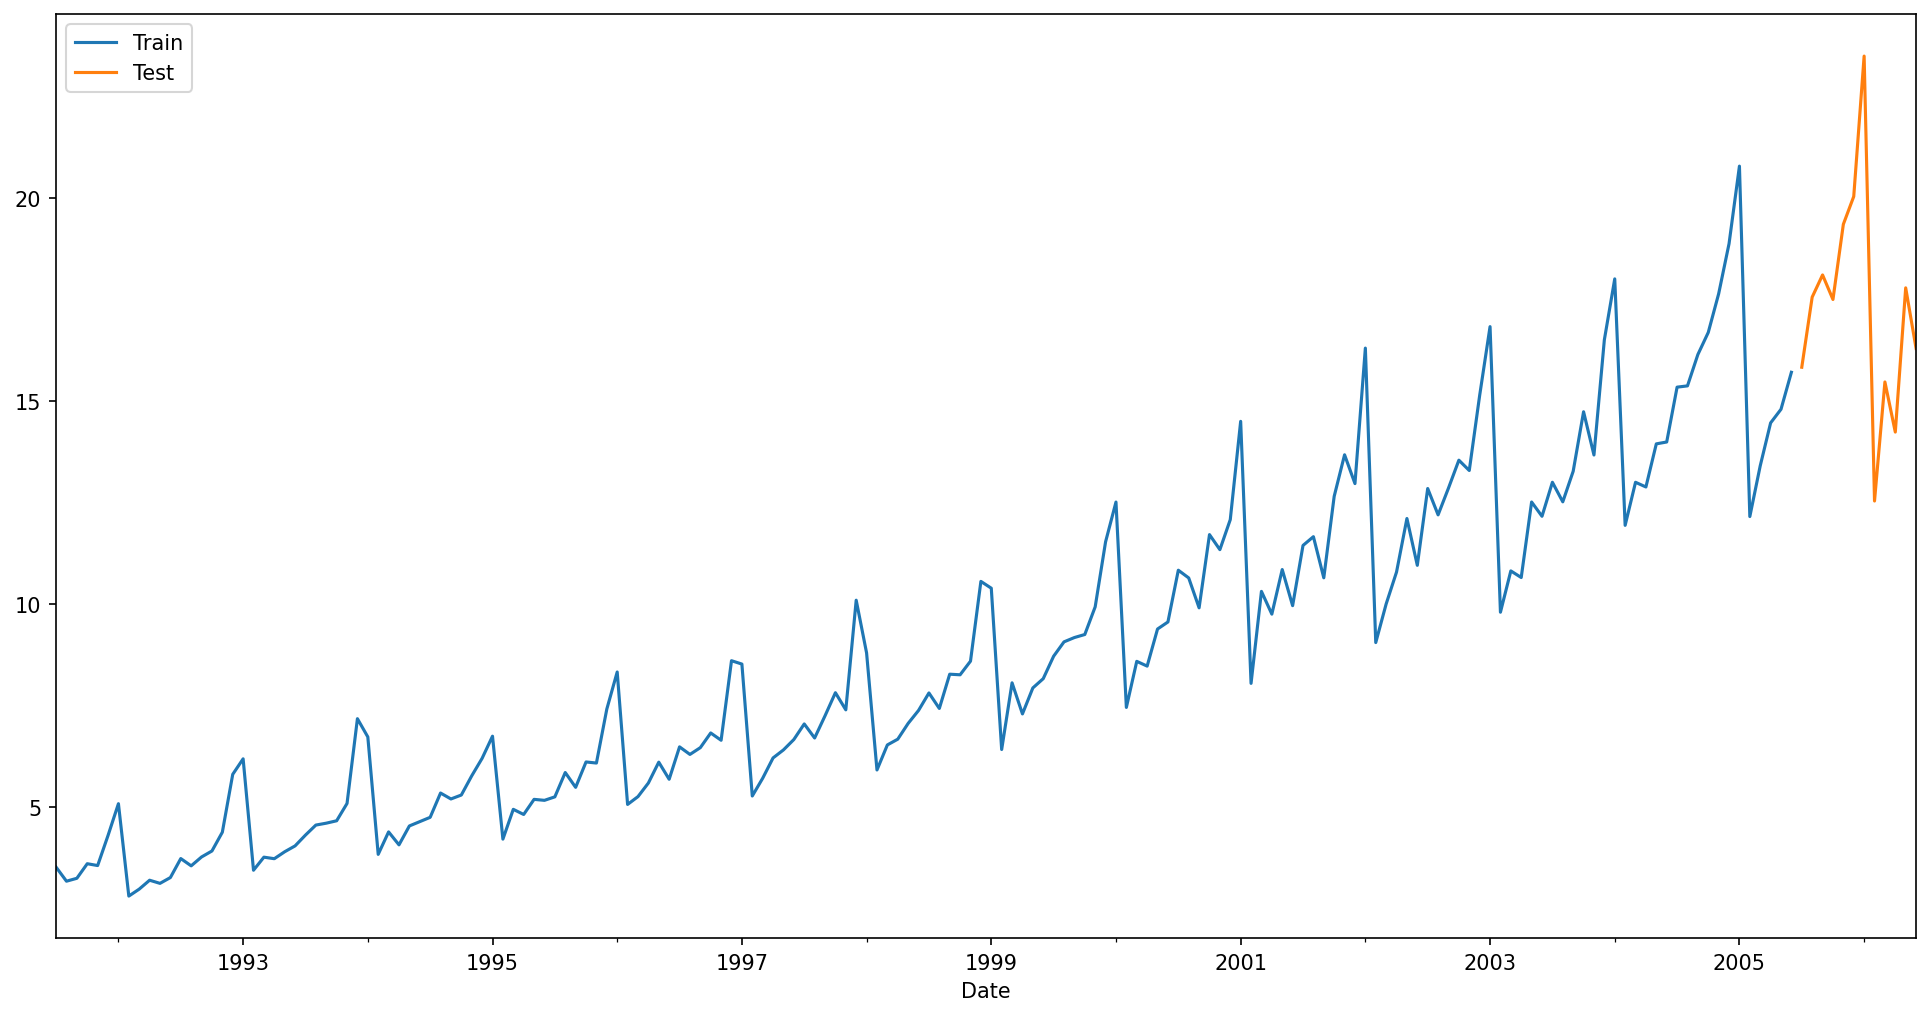

In [49]:
plt.figure(figsize=(16, 8), dpi=150)
train_data2['value'].plot(label='Train')
test_data2['value'].plot(label='Test')
plt.xlabel('Date')
plt.legend()
plt.show();

### ETS Model - Error trend and seasonality

#### Simple Exponential Smoothing

In [50]:
#First Instance
ins1 = SimpleExpSmoothing(train_data2).fit(smoothing_level=0.2,optimized=False)
ins_cast1 = ins1.forecast(12).rename('alpha=0.2')

#Second Instance
ins2 = SimpleExpSmoothing(train_data2).fit(smoothing_level=0.8,optimized=False)
ins_cast2 = ins2.forecast(12).rename('alpha=0.5')

#Third Instance
ins3 = SimpleExpSmoothing(train_data2).fit()
ins_cast3 = ins3.forecast(12).rename('alpha=%s'%ins3.model.params['smoothing_level'])

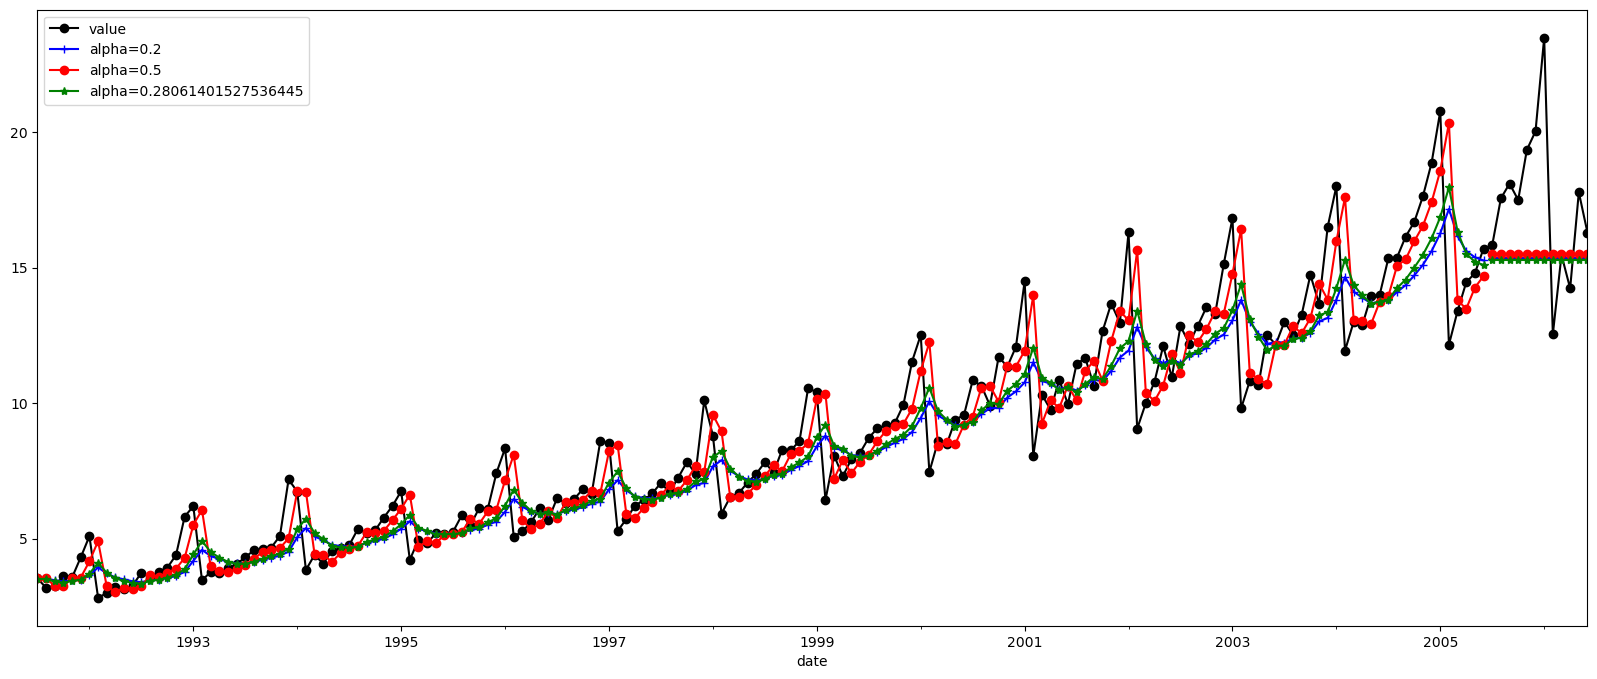

In [51]:
#After creating model we will visualize the plot
ax = dmed_2.plot(marker='o', color='black', figsize=(20,8), legend=True)

#Plot for alpha =0.2
ins_cast1.plot(marker='+', ax=ax, color='blue', legend=True)
ins1.fittedvalues.plot(marker='+', ax=ax, color='blue')

#Plot for alpha = 0.5
ins_cast2.plot(marker='o', ax=ax, color='red', legend=True)
ins2.fittedvalues.plot(marker='o', ax=ax, color='red')

#Plot for alpha=Optimized by statsmodel
ins_cast3.plot(marker='*', ax=ax, color='green', legend=True)
ins3.fittedvalues.plot(marker='*', ax=ax, color='green')

plt.show()

#### Double Exponential Smoothing 

In [52]:
double_ets_add = ExponentialSmoothing(train_data2, trend = 'add').fit()
double_ets_mul = ExponentialSmoothing(train_data2, trend = 'mul').fit()

double_ets_add_pred = double_ets_add.forecast(12)
double_ets_mul_pred = double_ets_mul.forecast(12)

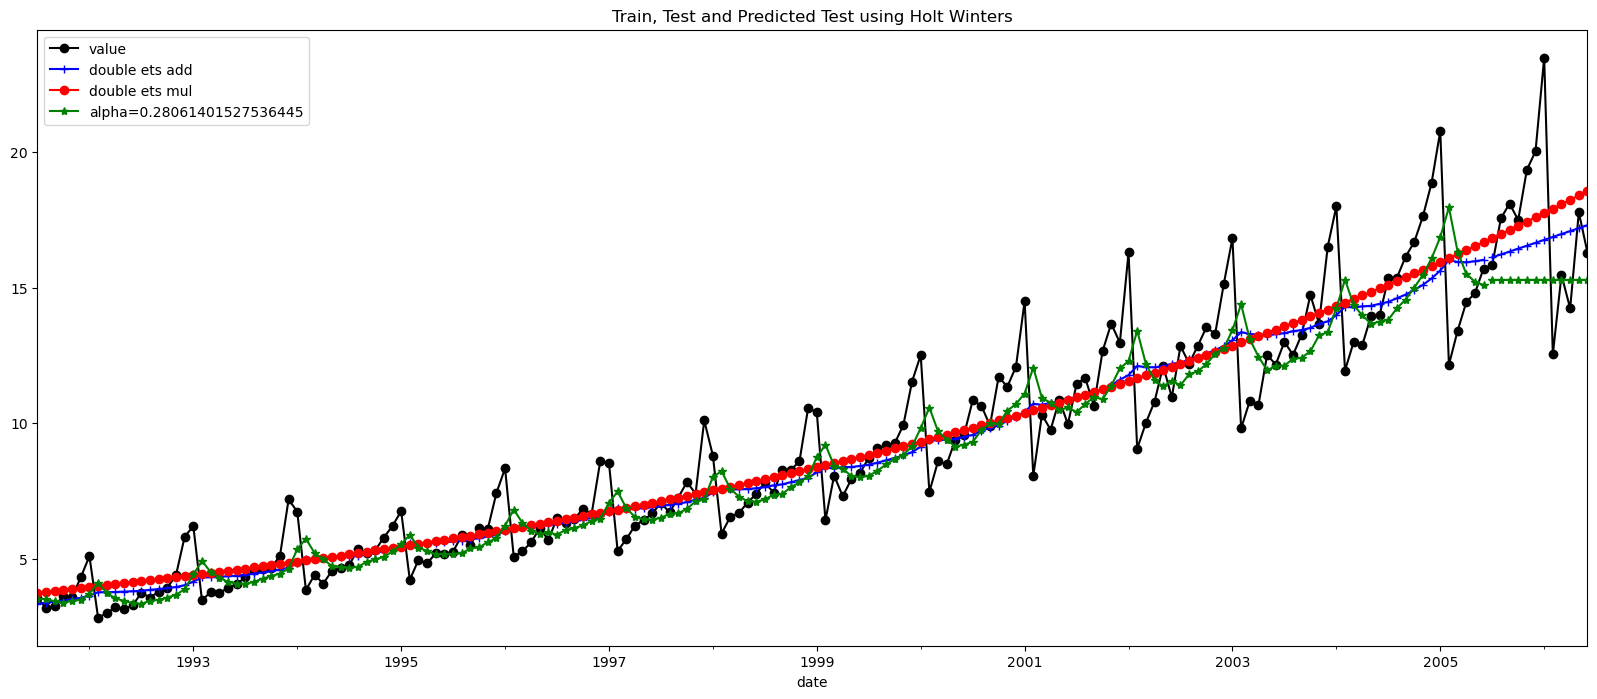

In [53]:
#plot the train, test, and predictions

#After creating model we will visualize the plot
ax = dmed_2.plot(marker='o', color='black', figsize=(20,8), legend=True)

#Plot for double ETS additive
double_ets_add_pred.plot(marker='+', ax=ax, color='blue', legend=True, label = 'double ets add')
double_ets_add.fittedvalues.plot(marker='+', ax=ax, color='blue')

#Plot for double ETS multiplicative
double_ets_mul_pred.plot(marker='o', ax=ax, color='red', legend=True, label = 'double ets mul')
double_ets_mul.fittedvalues.plot(marker='o', ax=ax, color='red')

#Plot for simple exponential smooting alpha=Optimized by statsmodel
ins_cast3.plot(marker='*', ax=ax, color='green', legend=True)
ins3.fittedvalues.plot(marker='*', ax=ax, color='green')
plt.title('Train, Test and Predicted Test using Holt Winters')
plt.show()

#### Triple Exponential Smoothing 

This is the extended version of simple exponential smoothing to allow the forecasting of data with a trend and seasonality.

In [54]:
# triple ETS - Holt Winter's Seasonal Method
triple_ets_add = ExponentialSmoothing(train_data2, trend = 'add', seasonal = 'add', seasonal_periods=12).fit()
triple_ets_mul = ExponentialSmoothing(train_data2, trend = 'mul', seasonal = 'mul', seasonal_periods=12).fit()

triple_ets_add_pred = triple_ets_add.forecast(12)
triple_ets_mul_pred = triple_ets_mul.forecast(12)

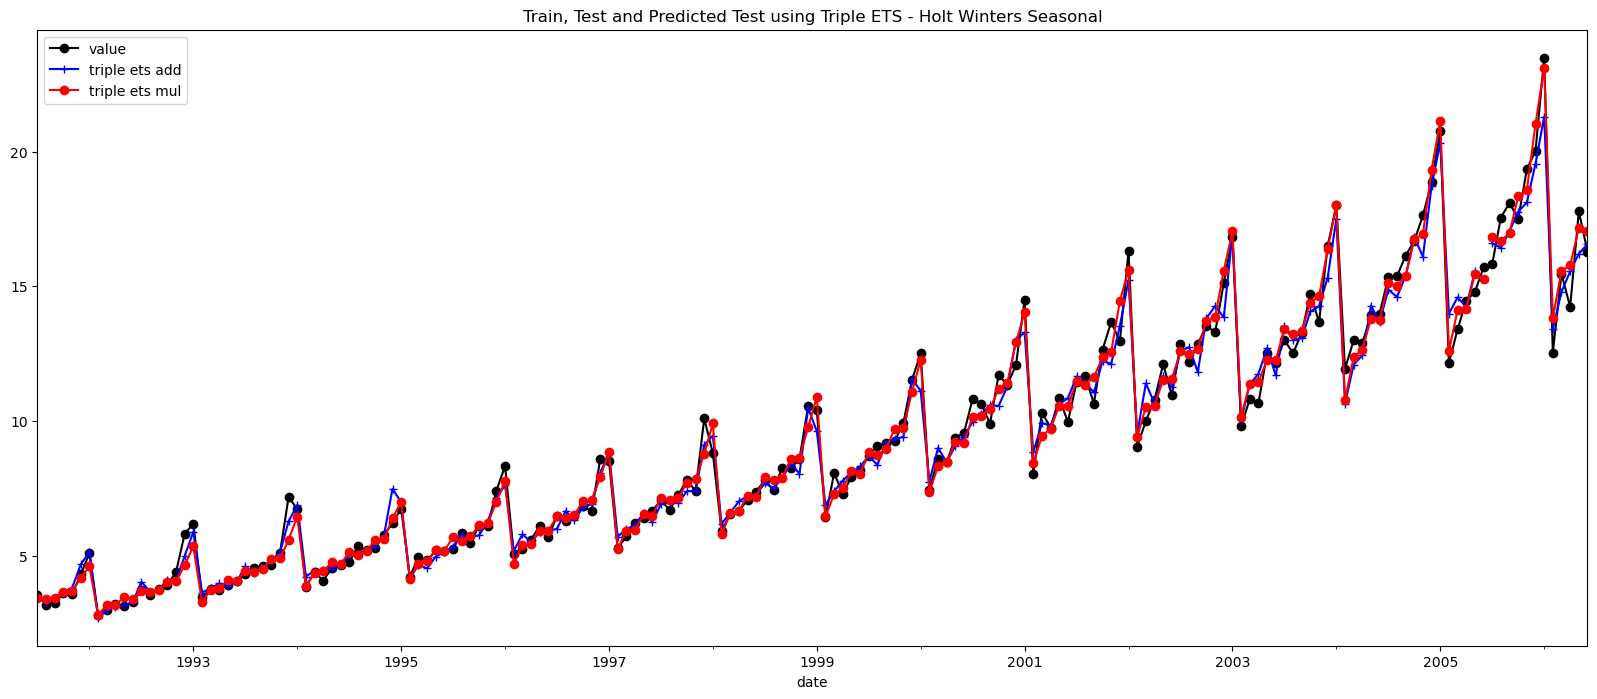

In [55]:
#plot the train, test, and predictions

#After creating model we will visualize the plot
ax = dmed_2.plot(marker='o', color='black', figsize=(20,8), legend=True)

#Plot for double ETS additive
triple_ets_add_pred.plot(marker='+', ax=ax, color='blue', legend=True, label = 'triple ets add')
triple_ets_add.fittedvalues.plot(marker='+', ax=ax, color='blue')

#Plot for double ETS multiplicative
triple_ets_mul_pred.plot(marker='o', ax=ax, color='red', legend=True, label = 'triple ets mul')
triple_ets_mul.fittedvalues.plot(marker='o', ax=ax, color='red')

plt.title('Train, Test and Predicted Test using Triple ETS - Holt Winters Seasonal')
plt.show()

#### Manual Arima

In [56]:
# p,d,q = 0,2,1 ARIMA Model
manual_model = sm.tsa.ARIMA(train_data2, order=(0,2,1))
manual_model_fit = manual_model.fit()
print(manual_model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                  value   No. Observations:                  168
Model:                 ARIMA(0, 2, 1)   Log Likelihood                -327.706
Date:                Fri, 18 Nov 2022   AIC                            659.411
Time:                        18:00:04   BIC                            665.635
Sample:                    07-01-1991   HQIC                           661.938
                         - 06-01-2005                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.9998      6.468     -0.155      0.877     -13.676      11.677
sigma2         2.9438     19.189      0.153      0.878     -34.665      40.553
Ljung-Box (L1) (Q):                  17.00   Jarque-

In [57]:
# Forecast
fc= manual_model_fit.forecast(12, alpha=0.05)  # 95% conf


In [58]:
conf= manual_model_fit.forecast(alpha=0.05)  # 95% conf


In [59]:
fc_series = pd.Series(fc, index=test_data2.index)
lower_series = pd.Series(conf, index=test_data2.index)
upper_series = pd.Series(conf, index=test_data2.index)


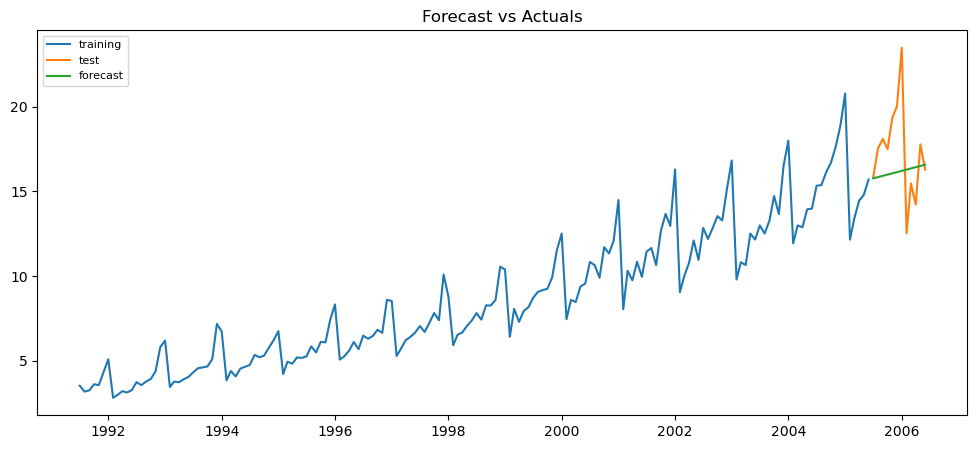

In [60]:
# Plot
plt.figure(figsize=(12,5), dpi=100)
plt.plot(train_data2, label='training')
plt.plot(test_data2, label='test')
plt.plot(fc_series, label='forecast')
plt.fill_between(lower_series.index, lower_series, upper_series, 
                 color='k', alpha=.15)
plt.title('Forecast vs Actuals')
plt.legend(loc='upper left', fontsize=8)
plt.show();


#### Auto ARIMA - Non Seasonal

In [61]:
non_seasonal_auto_model = pm.auto_arima(train_data2, start_p=0, start_q=0, 
                          test='adf',       # use adftest to find optimal 'd'
                          max_p=3, max_q=3, # maximum p and q
                          m=12,              # frequency of series
                          d=None,           # let model determine 'd'
                          seasonal=False,   # No Seasonality
                          trace=True,
                          error_action='ignore',  
                          suppress_warnings=True, 
                          stepwise=True)

print(non_seasonal_auto_model.summary())

Performing stepwise search to minimize aic
 ARIMA(0,0,0)(0,0,0)[0]             : AIC=1235.924, Time=0.02 sec
 ARIMA(1,0,0)(0,0,0)[0]             : AIC=663.903, Time=0.04 sec
 ARIMA(0,0,1)(0,0,0)[0]             : AIC=1060.107, Time=0.04 sec
 ARIMA(2,0,0)(0,0,0)[0]             : AIC=inf, Time=0.06 sec
 ARIMA(1,0,1)(0,0,0)[0]             : AIC=633.748, Time=0.06 sec
 ARIMA(2,0,1)(0,0,0)[0]             : AIC=624.012, Time=0.10 sec
 ARIMA(3,0,1)(0,0,0)[0]             : AIC=625.917, Time=0.12 sec
 ARIMA(2,0,2)(0,0,0)[0]             : AIC=634.244, Time=0.17 sec
 ARIMA(1,0,2)(0,0,0)[0]             : AIC=624.754, Time=0.09 sec
 ARIMA(3,0,0)(0,0,0)[0]             : AIC=inf, Time=0.05 sec
 ARIMA(3,0,2)(0,0,0)[0]             : AIC=643.635, Time=0.26 sec
 ARIMA(2,0,1)(0,0,0)[0] intercept   : AIC=624.552, Time=0.14 sec

Best model:  ARIMA(2,0,1)(0,0,0)[0]          
Total fit time: 1.160 seconds
                               SARIMAX Results                                
Dep. Variable:             

In [62]:
# Forecast
n_periods = 12
fc_auto_nonseasonal, confint = non_seasonal_auto_model.predict(n_periods=n_periods, return_conf_int=True)

In [63]:
fc_auto_nonseasonal

2005-07-01    15.441084
2005-08-01    15.353400
2005-09-01    15.320947
2005-10-01    15.305781
2005-11-01    15.296027
2005-12-01    15.287969
2006-01-01    15.280444
2006-02-01    15.273089
2006-03-01    15.265789
2006-04-01    15.258508
2006-05-01    15.251237
2006-06-01    15.243970
Freq: MS, dtype: float64

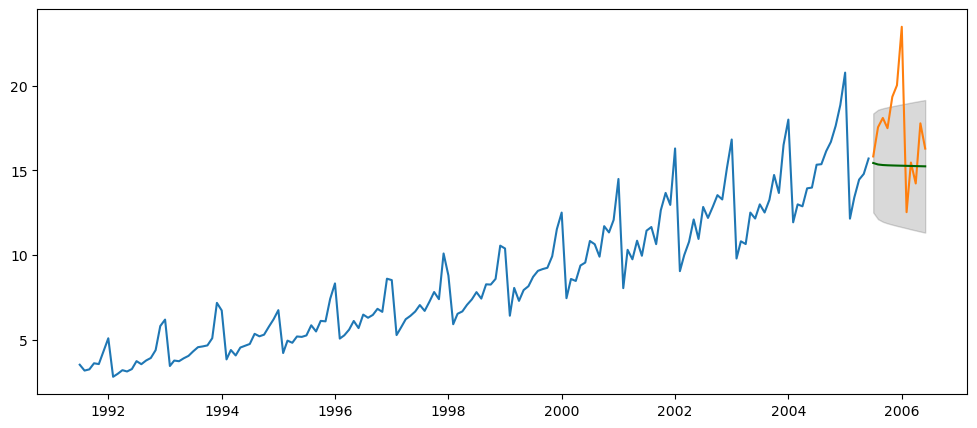

In [64]:
# make plot
fc_series_auto_nonseasonal = pd.Series(fc_auto_nonseasonal, index=test_data2.index)
lower_series = pd.Series(confint[:, 0], index=test_data2.index)
upper_series = pd.Series(confint[:, 1], index=test_data2.index)

# Plot
plt.figure(figsize=(12,5), dpi=100)
plt.plot(train_data2, label='train')
plt.plot(test_data2, label='test')
plt.plot(fc_series_auto_nonseasonal, color='darkgreen', label='forecast')
plt.fill_between(lower_series.index, 
                 lower_series, 
                 upper_series, 
                 color='k', alpha=.15)

plt.show()

#### Auto ARIMA Seasonal 

In [65]:
# Seasonal - fit stepwise auto-ARIMA
smodel = pm.auto_arima(train_data2, start_p=1, start_q=1,
                         test='adf',
                         max_p=3, max_q=3, m=12,
                         start_P=0, seasonal=True,
                         d=None, D=1, trace=True,
                         error_action='ignore',  
                         suppress_warnings=True, 
                         stepwise=True)

smodel.summary()

Performing stepwise search to minimize aic
 ARIMA(1,0,1)(0,1,1)[12] intercept   : AIC=277.978, Time=0.48 sec
 ARIMA(0,0,0)(0,1,0)[12] intercept   : AIC=328.707, Time=0.03 sec
 ARIMA(1,0,0)(1,1,0)[12] intercept   : AIC=307.343, Time=0.23 sec
 ARIMA(0,0,1)(0,1,1)[12] intercept   : AIC=317.216, Time=0.14 sec
 ARIMA(0,0,0)(0,1,0)[12]             : AIC=495.695, Time=0.02 sec
 ARIMA(1,0,1)(0,1,0)[12] intercept   : AIC=284.962, Time=0.14 sec
 ARIMA(1,0,1)(1,1,1)[12] intercept   : AIC=inf, Time=0.72 sec
 ARIMA(1,0,1)(0,1,2)[12] intercept   : AIC=278.584, Time=1.38 sec
 ARIMA(1,0,1)(1,1,0)[12] intercept   : AIC=281.078, Time=0.45 sec
 ARIMA(1,0,1)(1,1,2)[12] intercept   : AIC=inf, Time=1.64 sec
 ARIMA(1,0,0)(0,1,1)[12] intercept   : AIC=306.862, Time=0.15 sec
 ARIMA(2,0,1)(0,1,1)[12] intercept   : AIC=277.468, Time=0.48 sec
 ARIMA(2,0,1)(0,1,0)[12] intercept   : AIC=284.849, Time=0.13 sec
 ARIMA(2,0,1)(1,1,1)[12] intercept   : AIC=inf, Time=0.82 sec
 ARIMA(2,0,1)(0,1,2)[12] intercept   : AIC=27

<class 'statsmodels.iolib.summary.Summary'>
"""
                                      SARIMAX Results                                       
============================================================================================
Dep. Variable:                                    y   No. Observations:                  168
Model:             SARIMAX(3, 0, 0)x(0, 1, [1], 12)   Log Likelihood                -132.408
Date:                              Fri, 18 Nov 2022   AIC                            276.817
Time:                                      18:00:29   BIC                            295.116
Sample:                                  07-01-1991   HQIC                           284.249
                                       - 06-01-2005                                         
Covariance Type:                                opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.2327      0.085      2.747      0.006       0.067       0.399
ar.L1          0.1634      0.076      2.148      0.032       0.014       0.312
ar.L2          0.3017      0.067      4.503      0.000       0.170       0.433
ar.L3          0.2869      0.066      4.325      0.000       0.157       0.417
ma.S.L12      -0.3081      0.079     -3.915      0.000      -0.462      -0.154
sigma2         0.3159      0.035      8.903      0.000       0.246       0.386
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):                 3.75
Prob(Q):                              0.96   Prob(JB):                         0.15
Heteroskedasticity (H):               3.67   Skew:                            -0.04
Prob(H) (two-sided):                  0.00   Kurtosis:                         3.76
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [66]:
# Forecast
n_periods = 12
fc_auto_seasonal, confint = smodel.predict(n_periods=n_periods, return_conf_int=True)

In [67]:
fc_auto_seasonal

2005-07-01    16.360381
2005-08-01    16.193578
2005-09-01    17.011254
2005-10-01    17.621824
2005-11-01    18.045499
2005-12-01    19.594596
2006-01-01    21.373333
2006-02-01    13.432173
2006-03-01    14.597302
2006-04-01    15.278109
2006-05-01    15.876019
2006-06-01    16.445099
Freq: MS, dtype: float64

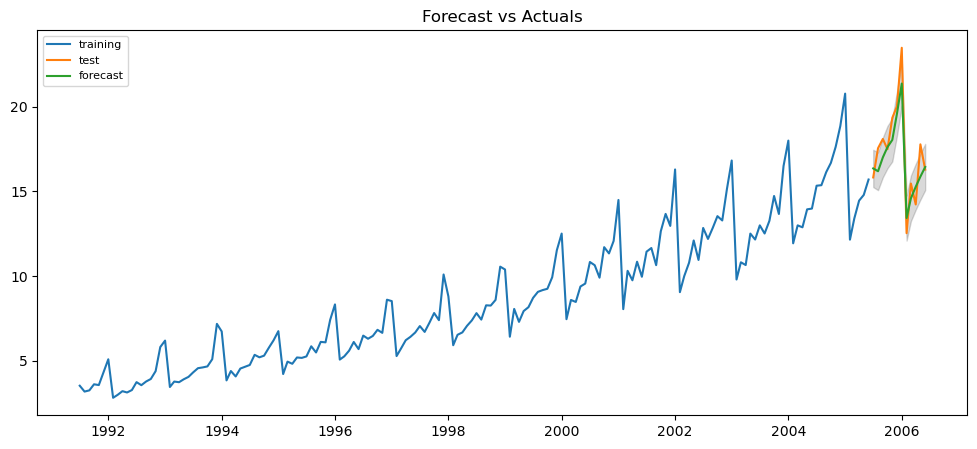

In [68]:
# make series for plotting purpose
fc_series_auto_seasonal = pd.Series(fc_auto_seasonal, index=test_data2.index)
lower_series = pd.Series(confint[:, 0], index=test_data2.index)
upper_series = pd.Series(confint[:, 1], index=test_data2.index)

# Plot
plt.figure(figsize=(12,5), dpi=100)
plt.plot(train_data2, label='training')
plt.plot(test_data2, label='test')
plt.plot(fc_series_auto_seasonal, label='forecast')
plt.fill_between(lower_series.index, lower_series, upper_series, 
                 color='k', alpha=.15)
plt.title('Forecast vs Actuals')
plt.legend(loc='upper left', fontsize=8)
plt.show()

#### Model Evaluation

In [69]:
#define metrics dataframe which will be used below for 
metrics_dataframe = pd.DataFrame(columns=['Model', 'RMSE', 'MAE', 'MAPE'])

                                 
def metrics_cal(actuals, predictions, model):
    mse = mean_squared_error(actuals, predictions)
    rmse = sqrt(mse)
    mae = mean_absolute_error(actuals, predictions)
    mape = np.mean(np.abs((actuals - predictions) / actuals)) * 100
    
    df = pd.DataFrame({'Model': model,
                       'RMSE': rmse,
                       'MAE': mae, 
                       'MAPE': mape}, index=[0])
    dataframe = metrics_dataframe.append(df)
    return dataframe

In [70]:
#get all the metrics

metrics_dataframe = metrics_cal(test_data2.values.flatten(), 
                                triple_ets_add_pred.values.flatten(), 
                                'Triple Add')

metrics_dataframe = metrics_cal(test_data2.values.flatten(), 
                                triple_ets_mul_pred.values.flatten(), 
                                'Triple Mul')

metrics_dataframe = metrics_cal(test_data2.values.flatten(), 
                                fc_series.values.flatten(), 
                                'Manual ARIMA')

metrics_dataframe = metrics_cal(test_data2.values.flatten(), 
                                fc_series_auto_nonseasonal.values.flatten(), 
                                'Auto ARIMA Non Seasonal')

metrics_dataframe = metrics_cal(test_data2.values.flatten(), 
                                fc_series_auto_seasonal.values.flatten(), 
                                'Auto ARIMA Seasonal')

In [71]:
metrics_dataframe.sort_values(by='MAE')

,Model,RMSE,MAE,MAPE
0,Triple Mul,0.935335,0.860370,5.248067
0,Auto ARIMA Seasonal,1.154635,0.985713,5.626408
0,Triple Add,1.122216,0.987610,5.665812
0,Manual ARIMA,3.028353,2.356663,13.171159
0,Auto ARIMA Non Seasonal,3.413987,2.675261,14.452221


In [72]:
# Create a data frame with all the predictions along with the test data
test_pred_df = test_data2.copy()

# Add all predictions 
test_pred_df = test_pred_df.assign(manual_arima_pred = fc_series.values.flatten(),
                                   auto_nonseasonal_pred = fc_series_auto_nonseasonal.values.flatten(),
                                   auto_seasonal_pred = fc_series_auto_seasonal.values.flatten(),
                                   avg_pred = (fc_series.values.flatten()+
                                               fc_series_auto_nonseasonal.values.flatten()+
                                               fc_series_auto_seasonal.values.flatten())/3)

test_pred_df

,value,manual_arima_pred,auto_nonseasonal_pred,auto_seasonal_pred,avg_pred
date,,,,,
2005-07-01,15.829550,15.778176,15.441084,16.360381,15.859881
2005-08-01,17.554701,15.851104,15.353400,16.193578,15.799361
2005-09-01,18.100864,15.924032,15.320947,17.011254,16.085411
2005-10-01,17.496668,15.996960,15.305781,17.621824,16.308188
2005-11-01,19.347265,16.069888,15.296027,18.045499,16.470472
2005-12-01,20.031291,16.142816,15.287969,19.594596,17.008461
2006-01-01,23.486694,16.215745,15.280444,21.373333,17.623174
2006-02-01,12.536987,16.288673,15.273089,13.432173,14.997978
2006-03-01,15.467018,16.361601,15.265789,14.597302,15.408230


In [73]:
metrics_dataframe = metrics_cal(test_data2.values.flatten(), 
                                test_pred_df['avg_pred'], 
                                'Average')

In [74]:
metrics_dataframe.sort_values(by='MAE')

,Model,RMSE,MAE,MAPE
0,Triple Mul,0.935335,0.860370,5.248067
0,Auto ARIMA Seasonal,1.154635,0.985713,5.626408
0,Triple Add,1.122216,0.987610,5.665812
0,Average,2.451298,1.900220,10.417013
0,Manual ARIMA,3.028353,2.356663,13.171159
0,Auto ARIMA Non Seasonal,3.413987,2.675261,14.452221


### Part 3: July 2006-June 2007

In [75]:
# create new subset data that ends 06/2007
dmed_3 = dmed['1991-07-01':'2007-06-01']

In [76]:
from sklearn.model_selection import train_test_split

train_data3, test_data3 = train_test_split(dmed_3, test_size=12, random_state=25, shuffle = False)
#shuffle = False is very important to ensure the order of the data

print(f"No. of training examples: {train_data3.shape[0]}")
print(f"No. of testing examples: {test_data3.shape[0]}")

No. of training examples: 180
No. of testing examples: 12


#### Plot train and test data for Period 3

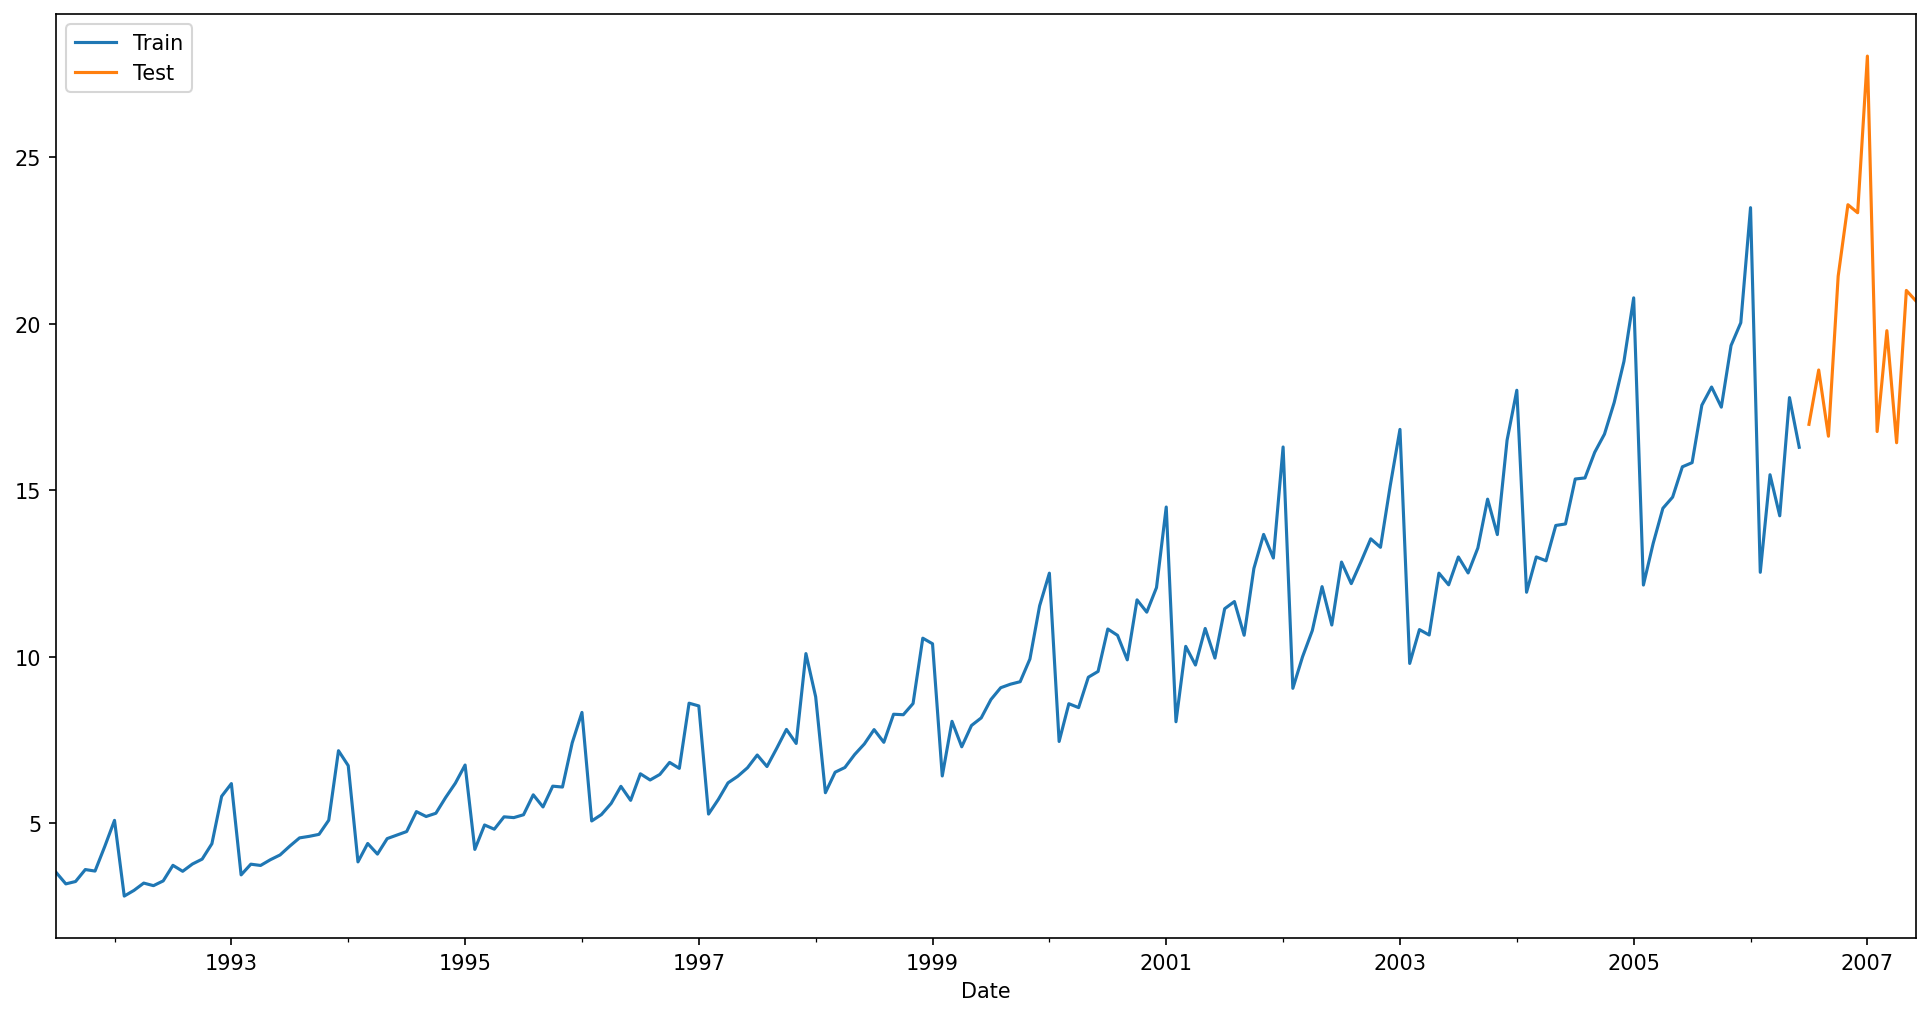

In [77]:
plt.figure(figsize=(16, 8), dpi=150)
train_data3['value'].plot(label='Train')
test_data3['value'].plot(label='Test')
plt.xlabel('Date')
plt.legend()
plt.show();

### ETS Model - Error trend and seasonality

#### Simple Exponential Smoothing

In [78]:
#First Instance
ins1 = SimpleExpSmoothing(train_data3).fit(smoothing_level=0.2,optimized=False)
ins_cast1 = ins1.forecast(12).rename('alpha=0.2')

#Second Instance
ins2 = SimpleExpSmoothing(train_data3).fit(smoothing_level=0.8,optimized=False)
ins_cast2 = ins2.forecast(12).rename('alpha=0.5')

#Third Instance
ins3 = SimpleExpSmoothing(train_data3).fit()
ins_cast3 = ins3.forecast(12).rename('alpha=%s'%ins3.model.params['smoothing_level'])

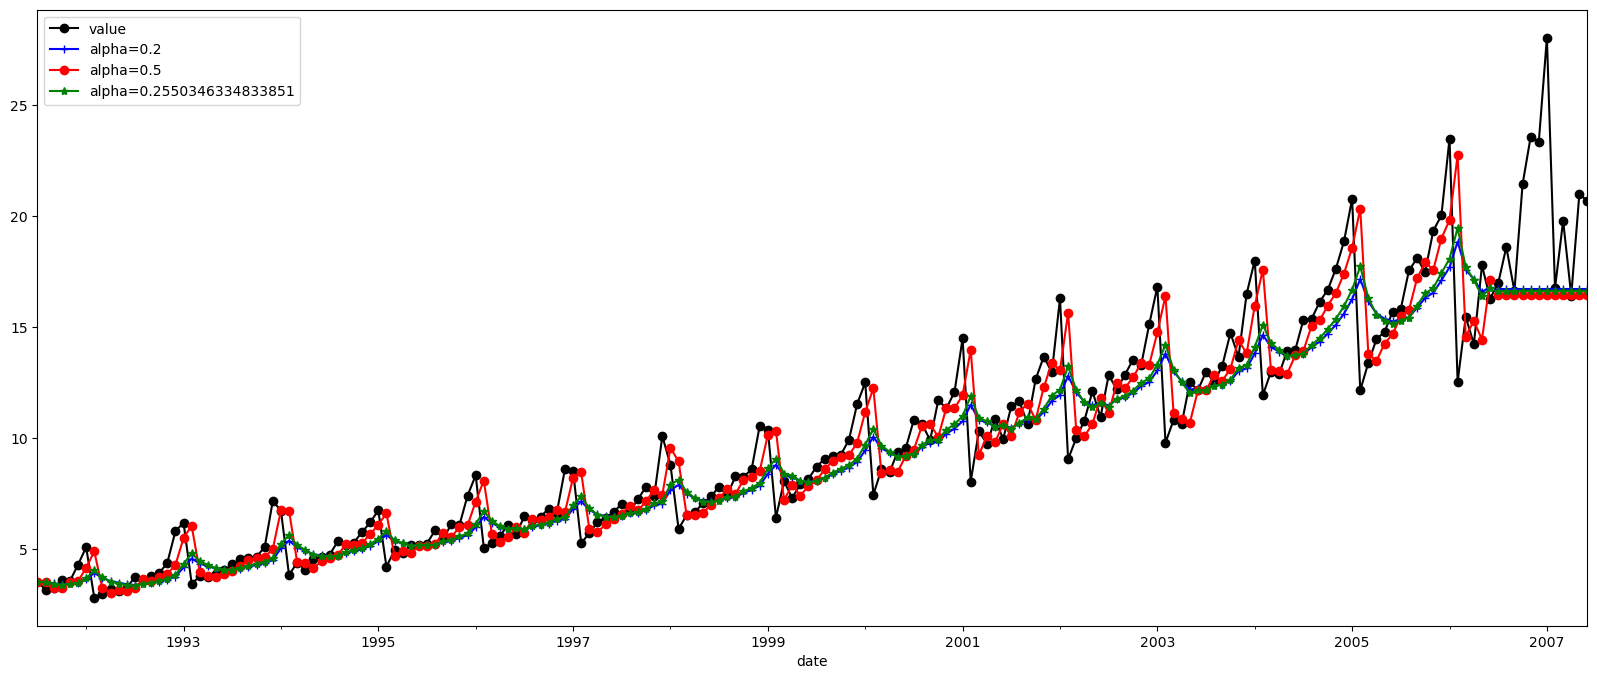

In [79]:
#After creating model we will visualize the plot
ax = dmed_3.plot(marker='o', color='black', figsize=(20,8), legend=True)

#Plot for alpha =0.2
ins_cast1.plot(marker='+', ax=ax, color='blue', legend=True)
ins1.fittedvalues.plot(marker='+', ax=ax, color='blue')

#Plot for alpha = 0.5
ins_cast2.plot(marker='o', ax=ax, color='red', legend=True)
ins2.fittedvalues.plot(marker='o', ax=ax, color='red')

#Plot for alpha=Optimized by statsmodel
ins_cast3.plot(marker='*', ax=ax, color='green', legend=True)
ins3.fittedvalues.plot(marker='*', ax=ax, color='green')

plt.show()

#### Double Exponential Smoothing 

In [80]:
double_ets_add = ExponentialSmoothing(train_data3, trend = 'add').fit()
double_ets_mul = ExponentialSmoothing(train_data3, trend = 'mul').fit()

double_ets_add_pred = double_ets_add.forecast(12)
double_ets_mul_pred = double_ets_mul.forecast(12)

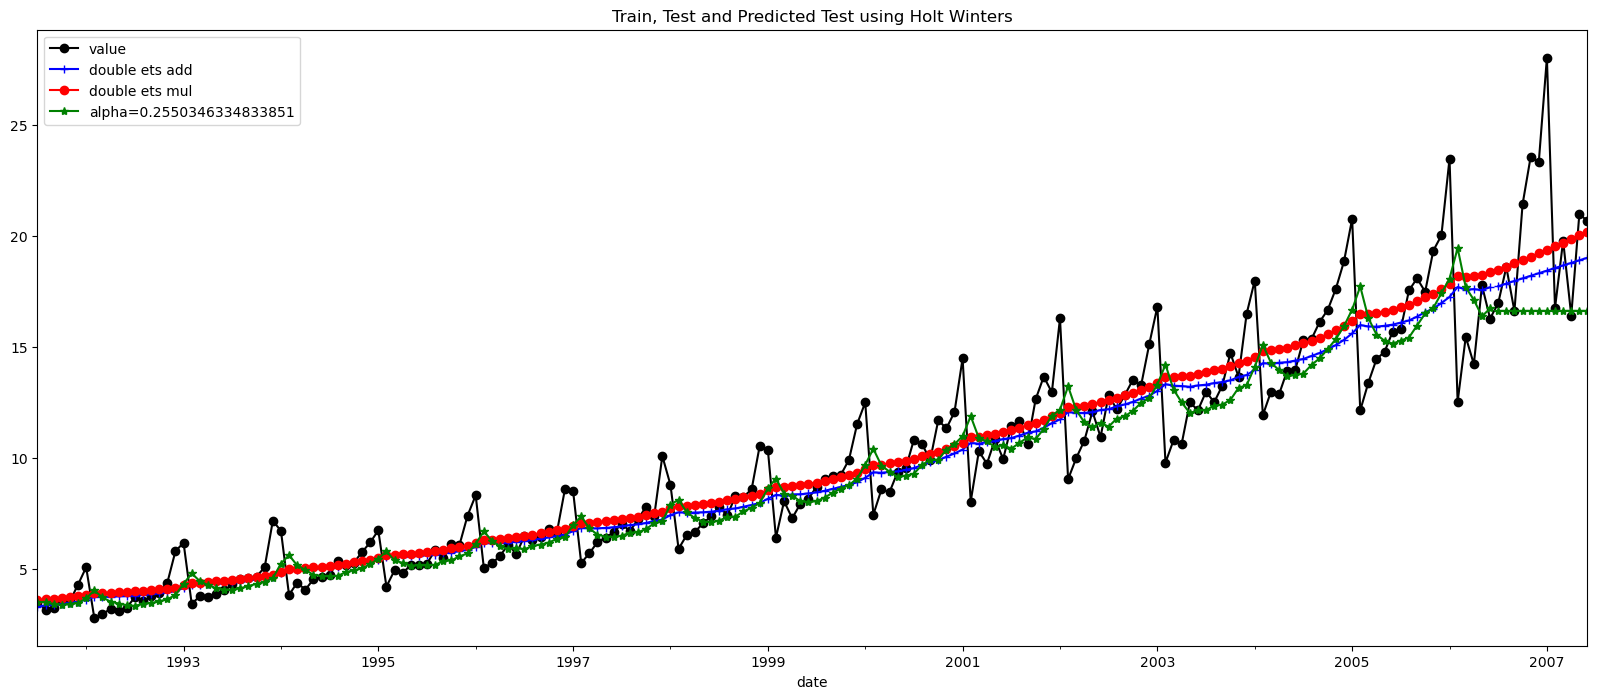

In [81]:
#plot the train, test, and predictions

#After creating model we will visualize the plot
ax = dmed_3.plot(marker='o', color='black', figsize=(20,8), legend=True)

#Plot for double ETS additive
double_ets_add_pred.plot(marker='+', ax=ax, color='blue', legend=True, label = 'double ets add')
double_ets_add.fittedvalues.plot(marker='+', ax=ax, color='blue')

#Plot for double ETS multiplicative
double_ets_mul_pred.plot(marker='o', ax=ax, color='red', legend=True, label = 'double ets mul')
double_ets_mul.fittedvalues.plot(marker='o', ax=ax, color='red')

#Plot for simple exponential smooting alpha=Optimized by statsmodel
ins_cast3.plot(marker='*', ax=ax, color='green', legend=True)
ins3.fittedvalues.plot(marker='*', ax=ax, color='green')
plt.title('Train, Test and Predicted Test using Holt Winters')
plt.show()

#### Triple Exponential Smoothing 

This is the extended version of simple exponential smoothing to allow the forecasting of data with a trend and seasonality.

In [82]:
# triple ETS - Holt Winter's Seasonal Method
triple_ets_add = ExponentialSmoothing(train_data3, trend = 'add', seasonal = 'add', seasonal_periods=12).fit()
triple_ets_mul = ExponentialSmoothing(train_data3, trend = 'mul', seasonal = 'mul', seasonal_periods=12).fit()

triple_ets_add_pred = triple_ets_add.forecast(12)
triple_ets_mul_pred = triple_ets_mul.forecast(12)

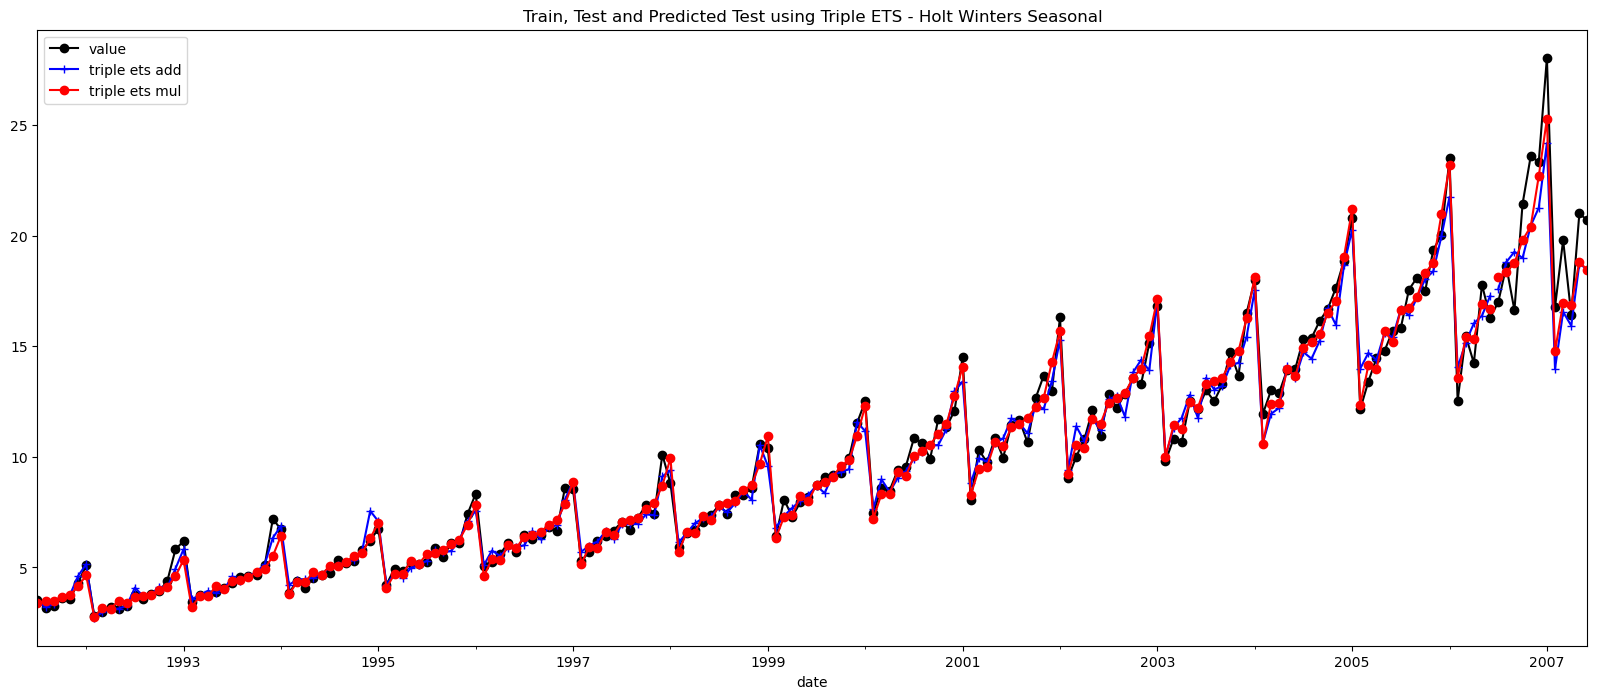

In [83]:
#plot the train, test, and predictions

#After creating model we will visualize the plot
ax = dmed_3.plot(marker='o', color='black', figsize=(20,8), legend=True)

#Plot for double ETS additive
triple_ets_add_pred.plot(marker='+', ax=ax, color='blue', legend=True, label = 'triple ets add')
triple_ets_add.fittedvalues.plot(marker='+', ax=ax, color='blue')

#Plot for double ETS multiplicative
triple_ets_mul_pred.plot(marker='o', ax=ax, color='red', legend=True, label = 'triple ets mul')
triple_ets_mul.fittedvalues.plot(marker='o', ax=ax, color='red')

plt.title('Train, Test and Predicted Test using Triple ETS - Holt Winters Seasonal')
plt.show()

#### Manual Arima

In [84]:
# p,d,q = 0,2,1 ARIMA Model
manual_model = sm.tsa.ARIMA(train_data3, order=(0,2,1))
manual_model_fit = manual_model.fit()
print(manual_model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                  value   No. Observations:                  180
Model:                 ARIMA(0, 2, 1)   Log Likelihood                -370.831
Date:                Fri, 18 Nov 2022   AIC                            745.663
Time:                        18:00:46   BIC                            752.026
Sample:                    07-01-1991   HQIC                           748.243
                         - 06-01-2006                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.9998      5.671     -0.176      0.860     -12.114      10.114
sigma2         3.6683     20.973      0.175      0.861     -37.437      44.774
Ljung-Box (L1) (Q):                  23.44   Jarque-

In [85]:
# Forecast
fc= manual_model_fit.forecast(12, alpha=0.05)  # 95% conf


In [86]:
conf= manual_model_fit.forecast(alpha=0.05)  # 95% conf


In [87]:
fc_series = pd.Series(fc, index=test_data3.index)
lower_series = pd.Series(conf, index=test_data3.index)
upper_series = pd.Series(conf, index=test_data3.index)


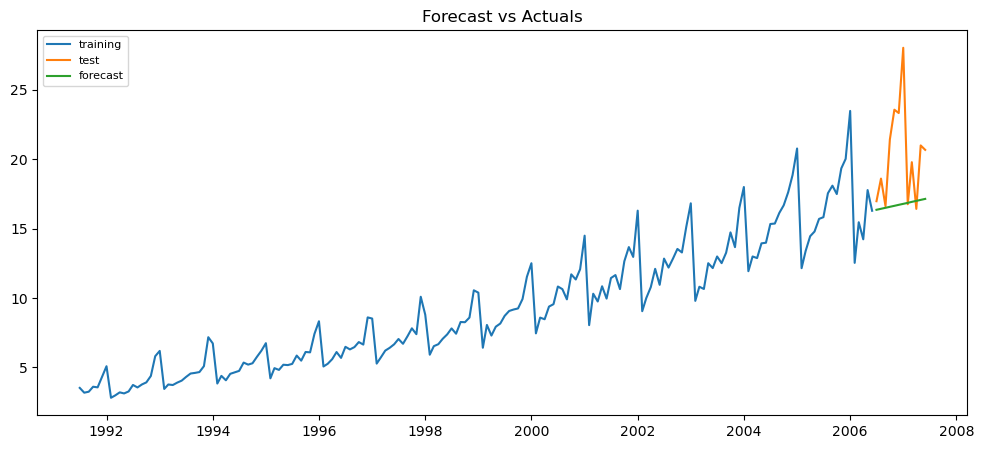

In [88]:
# Plot
plt.figure(figsize=(12,5), dpi=100)
plt.plot(train_data3, label='training')
plt.plot(test_data3, label='test')
plt.plot(fc_series, label='forecast')
plt.fill_between(lower_series.index, lower_series, upper_series, 
                 color='k', alpha=.15)
plt.title('Forecast vs Actuals')
plt.legend(loc='upper left', fontsize=8)
plt.show();


#### Auto ARIMA - Non Seasonal

In [89]:
non_seasonal_auto_model = pm.auto_arima(train_data3, start_p=0, start_q=0, 
                          test='adf',       # use adftest to find optimal 'd'
                          max_p=3, max_q=3, # maximum p and q
                          m=12,              # frequency of series
                          d=None,           # let model determine 'd'
                          seasonal=False,   # No Seasonality
                          trace=True,
                          error_action='ignore',  
                          suppress_warnings=True, 
                          stepwise=True)

print(non_seasonal_auto_model.summary())

Performing stepwise search to minimize aic
 ARIMA(0,0,0)(0,0,0)[0]             : AIC=1350.798, Time=0.02 sec
 ARIMA(1,0,0)(0,0,0)[0]             : AIC=750.098, Time=0.03 sec
 ARIMA(0,0,1)(0,0,0)[0]             : AIC=1165.103, Time=0.03 sec
 ARIMA(2,0,0)(0,0,0)[0]             : AIC=inf, Time=0.05 sec
 ARIMA(1,0,1)(0,0,0)[0]             : AIC=711.946, Time=0.06 sec
 ARIMA(2,0,1)(0,0,0)[0]             : AIC=703.384, Time=0.10 sec
 ARIMA(3,0,1)(0,0,0)[0]             : AIC=705.294, Time=0.16 sec
 ARIMA(2,0,2)(0,0,0)[0]             : AIC=710.434, Time=0.14 sec
 ARIMA(1,0,2)(0,0,0)[0]             : AIC=705.089, Time=0.08 sec
 ARIMA(3,0,0)(0,0,0)[0]             : AIC=inf, Time=0.05 sec
 ARIMA(3,0,2)(0,0,0)[0]             : AIC=695.975, Time=0.19 sec
 ARIMA(3,0,3)(0,0,0)[0]             : AIC=695.580, Time=0.26 sec
 ARIMA(2,0,3)(0,0,0)[0]             : AIC=695.085, Time=0.17 sec
 ARIMA(1,0,3)(0,0,0)[0]             : AIC=704.127, Time=0.10 sec
 ARIMA(2,0,3)(0,0,0)[0] intercept   : AIC=698.869, Ti

In [90]:
# Forecast
n_periods = 12
fc_auto_nonseasonal, confint = non_seasonal_auto_model.predict(n_periods=n_periods, return_conf_int=True)

In [91]:
fc_auto_nonseasonal

2006-07-01    17.206738
2006-08-01    16.129604
2006-09-01    17.292511
2006-10-01    16.117617
2006-11-01    17.274404
2006-12-01    16.105627
2007-01-01    17.256328
2007-02-01    16.093636
2007-03-01    17.238281
2007-04-01    16.081641
2007-05-01    17.220263
2007-06-01    16.069645
Freq: MS, dtype: float64

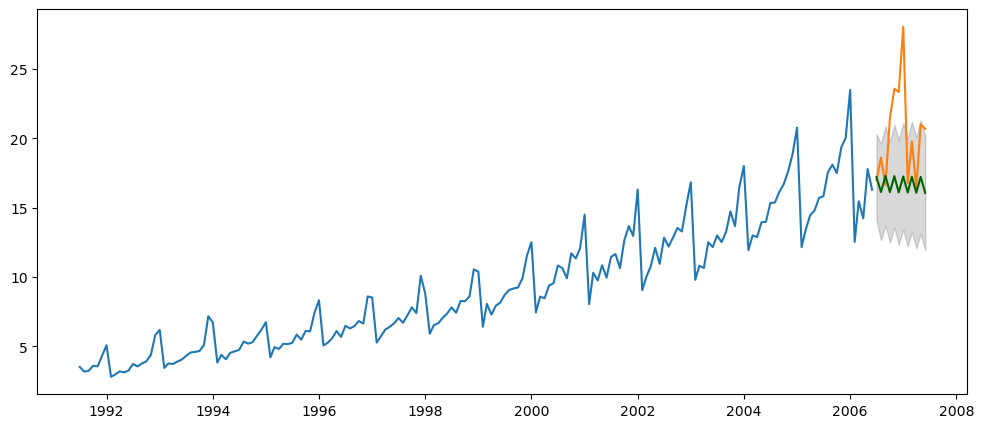

In [92]:
# make plot
fc_series_auto_nonseasonal = pd.Series(fc_auto_nonseasonal, index=test_data3.index)
lower_series = pd.Series(confint[:, 0], index=test_data3.index)
upper_series = pd.Series(confint[:, 1], index=test_data3.index)

# Plot
plt.figure(figsize=(12,5), dpi=100)
plt.plot(train_data3, label='train')
plt.plot(test_data3, label='test')
plt.plot(fc_series_auto_nonseasonal, color='darkgreen', label='forecast')
plt.fill_between(lower_series.index, 
                 lower_series, 
                 upper_series, 
                 color='k', alpha=.15)

plt.show()

#### Auto ARIMA Seasonal 

In [93]:
# Seasonal - fit stepwise auto-ARIMA
smodel = pm.auto_arima(train_data3, start_p=1, start_q=1,
                         test='adf',
                         max_p=3, max_q=3, m=12,
                         start_P=0, seasonal=True,
                         d=None, D=1, trace=True,
                         error_action='ignore',  
                         suppress_warnings=True, 
                         stepwise=True)

smodel.summary()

Performing stepwise search to minimize aic
 ARIMA(1,0,1)(0,1,1)[12] intercept   : AIC=331.086, Time=0.56 sec
 ARIMA(0,0,0)(0,1,0)[12] intercept   : AIC=369.596, Time=0.04 sec
 ARIMA(1,0,0)(1,1,0)[12] intercept   : AIC=362.402, Time=0.22 sec
 ARIMA(0,0,1)(0,1,1)[12] intercept   : AIC=367.046, Time=0.13 sec
 ARIMA(0,0,0)(0,1,0)[12]             : AIC=546.314, Time=0.02 sec
 ARIMA(1,0,1)(0,1,0)[12] intercept   : AIC=332.975, Time=0.18 sec
 ARIMA(1,0,1)(1,1,1)[12] intercept   : AIC=inf, Time=0.81 sec
 ARIMA(1,0,1)(0,1,2)[12] intercept   : AIC=329.553, Time=1.44 sec
 ARIMA(1,0,1)(1,1,2)[12] intercept   : AIC=335.076, Time=1.77 sec
 ARIMA(0,0,1)(0,1,2)[12] intercept   : AIC=368.302, Time=0.30 sec
 ARIMA(1,0,0)(0,1,2)[12] intercept   : AIC=362.333, Time=0.47 sec
 ARIMA(2,0,1)(0,1,2)[12] intercept   : AIC=323.157, Time=0.77 sec
 ARIMA(2,0,1)(0,1,1)[12] intercept   : AIC=323.874, Time=0.40 sec
 ARIMA(2,0,1)(1,1,2)[12] intercept   : AIC=325.560, Time=1.94 sec
 ARIMA(2,0,1)(1,1,1)[12] intercept   

<class 'statsmodels.iolib.summary.Summary'>
"""
                                        SARIMAX Results                                        
===============================================================================================
Dep. Variable:                                       y   No. Observations:                  180
Model:             SARIMAX(2, 0, 1)x(0, 1, [1, 2], 12)   Log Likelihood                -154.579
Date:                                 Fri, 18 Nov 2022   AIC                            323.157
Time:                                         18:01:13   BIC                            345.025
Sample:                                     07-01-1991   HQIC                           332.032
                                          - 06-01-2006                                         
Covariance Type:                                   opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.1151      0.062      1.859      0.063      -0.006       0.236
ar.L1          0.5565      0.127      4.369      0.000       0.307       0.806
ar.L2          0.3255      0.095      3.413      0.001       0.139       0.512
ma.L1         -0.4932      0.125     -3.938      0.000      -0.739      -0.248
ma.S.L12      -0.1377      0.078     -1.766      0.077      -0.291       0.015
ma.S.L24      -0.1445      0.087     -1.654      0.098      -0.316       0.027
sigma2         0.3655      0.035     10.486      0.000       0.297       0.434
===================================================================================
Ljung-Box (L1) (Q):                   0.01   Jarque-Bera (JB):                10.89
Prob(Q):                              0.93   Prob(JB):                         0.00
Heteroskedasticity (H):               4.36   Skew:                            -0.19
Prob(H) (two-sided):                  0.00   Kurtosis:                         4.19
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [94]:
# Forecast
n_periods = 12
fc_auto_seasonal, confint = smodel.predict(n_periods=n_periods, return_conf_int=True)

In [95]:
fc_auto_seasonal

2006-07-01    17.361045
2006-08-01    18.431793
2006-09-01    19.036000
2006-10-01    18.661523
2006-11-01    20.104599
2006-12-01    20.996593
2007-01-01    24.184384
2007-02-01    13.921592
2007-03-01    16.571242
2007-04-01    15.456397
2007-05-01    18.677867
2007-06-01    17.327955
Freq: MS, dtype: float64

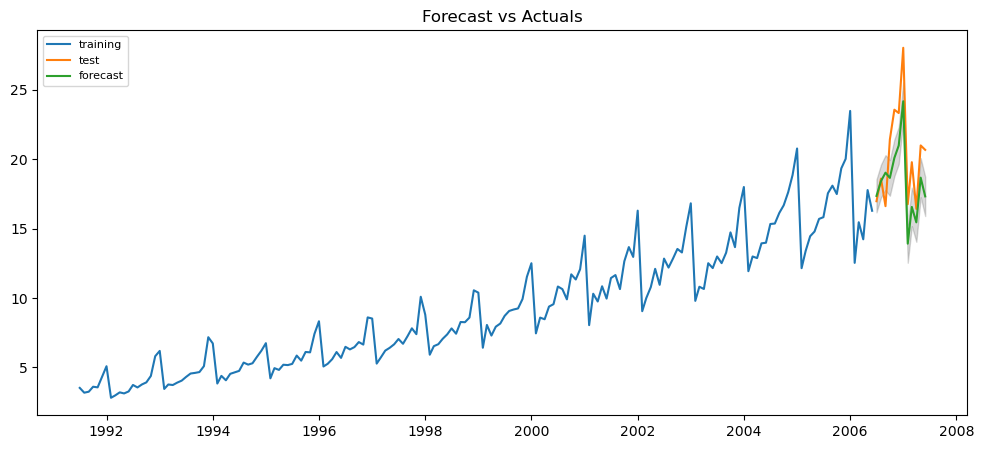

In [96]:
# make series for plotting purpose
fc_series_auto_seasonal = pd.Series(fc_auto_seasonal, index=test_data3.index)
lower_series = pd.Series(confint[:, 0], index=test_data3.index)
upper_series = pd.Series(confint[:, 1], index=test_data3.index)

# Plot
plt.figure(figsize=(12,5), dpi=100)
plt.plot(train_data3, label='training')
plt.plot(test_data3, label='test')
plt.plot(fc_series_auto_seasonal, label='forecast')
plt.fill_between(lower_series.index, lower_series, upper_series, 
                 color='k', alpha=.15)
plt.title('Forecast vs Actuals')
plt.legend(loc='upper left', fontsize=8)
plt.show()

#### Model Evaluation

In [97]:
#define metrics dataframe which will be used below for 
metrics_dataframe = pd.DataFrame(columns=['Model', 'RMSE', 'MAE', 'MAPE'])

                                 
def metrics_cal(actuals, predictions, model):
    mse = mean_squared_error(actuals, predictions)
    rmse = sqrt(mse)
    mae = mean_absolute_error(actuals, predictions)
    mape = np.mean(np.abs((actuals - predictions) / actuals)) * 100
    
    df = pd.DataFrame({'Model': model,
                       'RMSE': rmse,
                       'MAE': mae, 
                       'MAPE': mape}, index=[0])
    dataframe = metrics_dataframe.append(df)
    return dataframe

In [98]:
#get all the metrics
metrics_dataframe = metrics_cal(test_data3.values.flatten(), 
                                triple_ets_add_pred.values.flatten(), 
                                'Triple Add')

metrics_dataframe = metrics_cal(test_data3.values.flatten(), 
                                triple_ets_mul_pred.values.flatten(), 
                                'Triple Mul')

metrics_dataframe = metrics_cal(test_data3.values.flatten(), 
                                fc_series.values.flatten(), 
                                'Manual ARIMA')

metrics_dataframe = metrics_cal(test_data3.values.flatten(), 
                                fc_series_auto_nonseasonal.values.flatten(), 
                                'Auto ARIMA Non Seasonal')

metrics_dataframe = metrics_cal(test_data3.values.flatten(), 
                                fc_series_auto_seasonal.values.flatten(), 
                                'Auto ARIMA Seasonal')

In [99]:
metrics_dataframe.sort_values(by='MAE')

,Model,RMSE,MAE,MAPE
0,Triple Mul,2.018327,1.789538,8.743222
0,Triple Add,2.434020,2.165085,10.456239
0,Auto ARIMA Seasonal,2.615137,2.342974,11.295529
0,Manual ARIMA,4.859297,3.629124,15.905173
0,Auto ARIMA Non Seasonal,4.879771,3.747065,16.579662


In [100]:
# Create a data frame with all the predictions along with the test data
test_pred_df = test_data3.copy()

# Add all predictions 
test_pred_df = test_pred_df.assign(manual_arima_pred = fc_series.values.flatten(),
                                   auto_nonseasonal_pred = fc_series_auto_nonseasonal.values.flatten(),
                                   auto_seasonal_pred = fc_series_auto_seasonal.values.flatten(),
                                   avg_pred = (fc_series.values.flatten()+
                                               fc_series_auto_nonseasonal.values.flatten()+
                                               fc_series_auto_seasonal.values.flatten())/3)

test_pred_df

,value,manual_arima_pred,auto_nonseasonal_pred,auto_seasonal_pred,avg_pred
date,,,,,
2006-07-01,16.980282,16.362916,17.206738,17.361045,16.976899
2006-08-01,18.612189,16.434230,16.129604,18.431793,16.998542
2006-09-01,16.623343,16.505544,17.292511,19.036000,17.611352
2006-10-01,21.430241,16.576858,16.117617,18.661523,17.118666
2006-11-01,23.575517,16.648172,17.274404,20.104599,18.009058
2006-12-01,23.334206,16.719485,16.105627,20.996593,17.940569
2007-01-01,28.038383,16.790799,17.256328,24.184384,19.410504
2007-02-01,16.763869,16.862113,16.093636,13.921592,15.625780
2007-03-01,19.792754,16.933427,17.238281,16.571242,16.914317


In [101]:
metrics_dataframe = metrics_cal(test_data3.values.flatten(), 
                                test_pred_df['avg_pred'], 
                                'Average')

In [102]:
metrics_dataframe.sort_values(by='MAE')

,Model,RMSE,MAE,MAPE
0,Triple Mul,2.018327,1.789538,8.743222
0,Triple Add,2.434020,2.165085,10.456239
0,Auto ARIMA Seasonal,2.615137,2.342974,11.295529
0,Average,4.001990,3.161904,14.127577
0,Manual ARIMA,4.859297,3.629124,15.905173
0,Auto ARIMA Non Seasonal,4.879771,3.747065,16.579662


### Part 4: July 2007-June 2008

In [103]:
# create new subset data that ends 06/2008
dmed_4 = dmed['1991-07-01':'2008-06-01']

In [104]:
from sklearn.model_selection import train_test_split

train_data4, test_data4 = train_test_split(dmed_4, test_size=12, random_state=25, shuffle = False)
#shuffle = False is very important to ensure the order of the data

print(f"No. of training examples: {train_data4.shape[0]}")
print(f"No. of testing examples: {test_data4.shape[0]}")

No. of training examples: 192
No. of testing examples: 12


#### Plot train and test data for Period 2

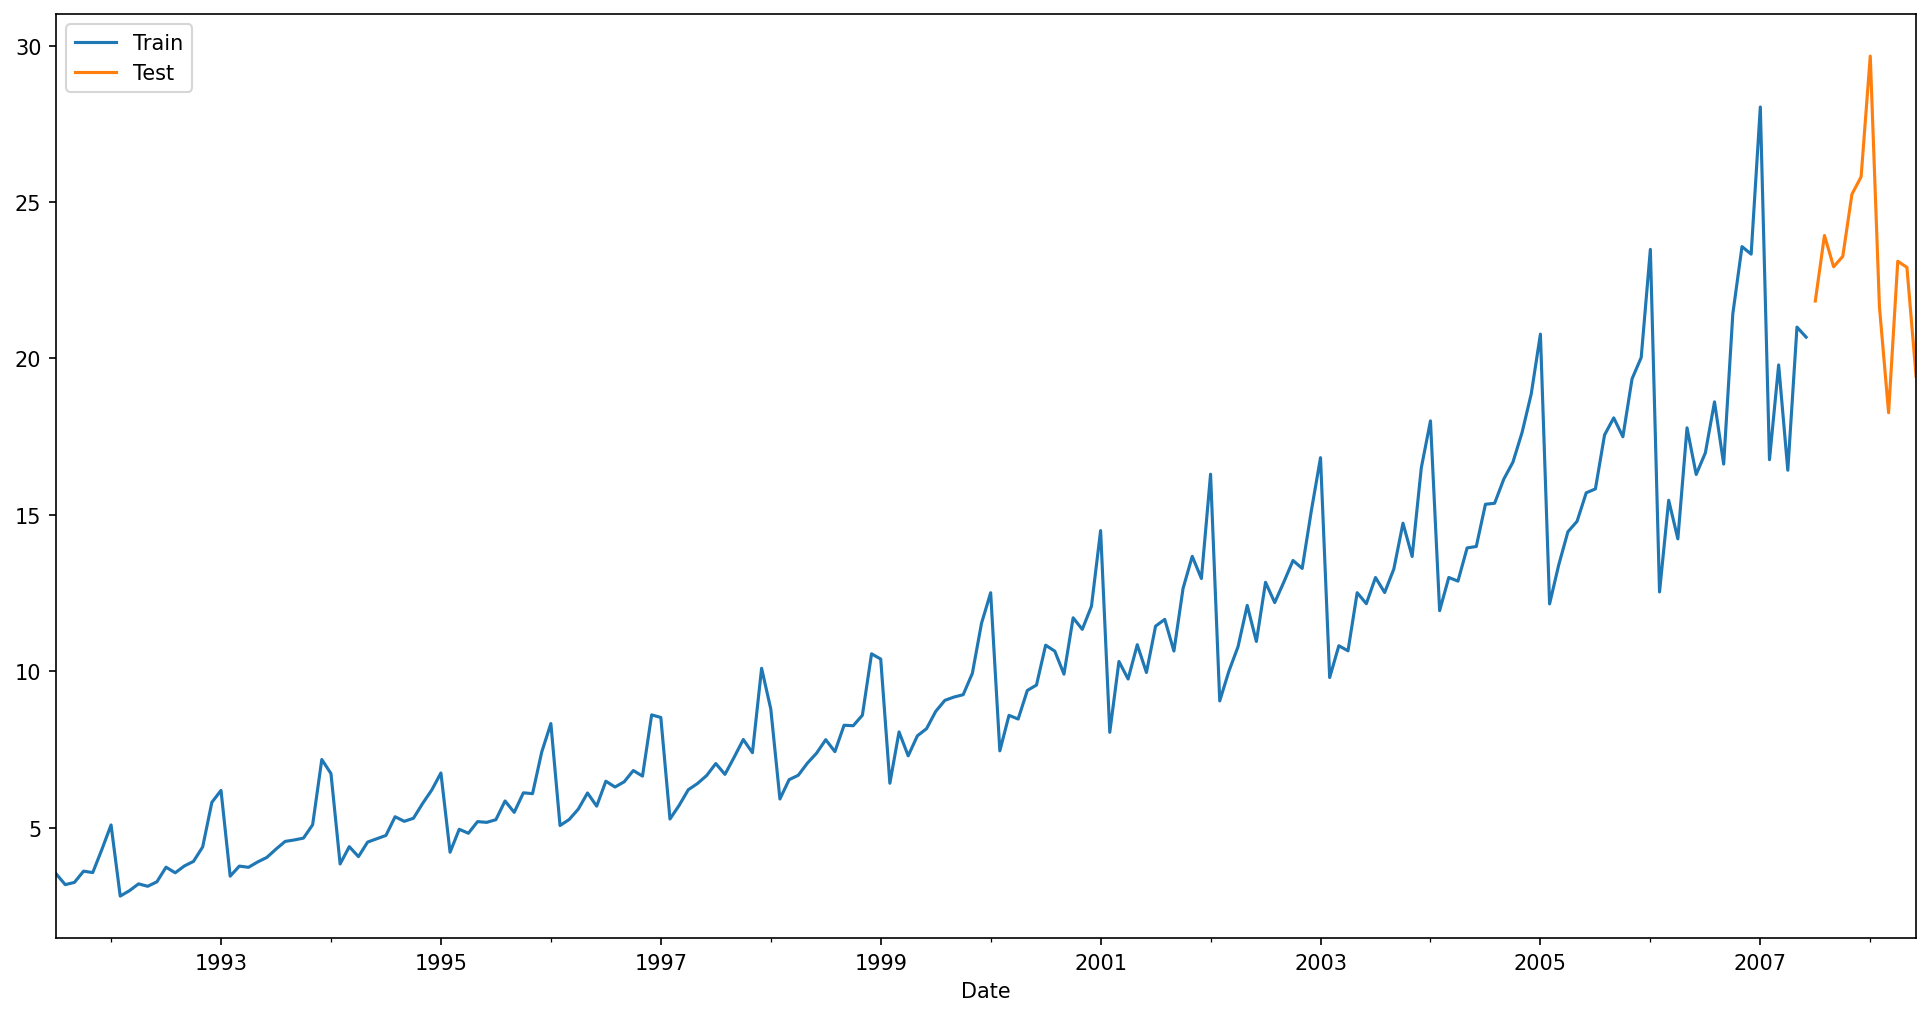

In [105]:
plt.figure(figsize=(16, 8), dpi=150)
train_data4['value'].plot(label='Train')
test_data4['value'].plot(label='Test')
plt.xlabel('Date')
plt.legend()
plt.show();

### ETS Model - Error trend and seasonality

#### Simple Exponential Smoothing

In [106]:
#First Instance
ins1 = SimpleExpSmoothing(train_data4).fit(smoothing_level=0.2,optimized=False)
ins_cast1 = ins1.forecast(12).rename('alpha=0.2')

#Second Instance
ins2 = SimpleExpSmoothing(train_data4).fit(smoothing_level=0.8,optimized=False)
ins_cast2 = ins2.forecast(12).rename('alpha=0.5')

#Third Instance
ins3 = SimpleExpSmoothing(train_data4).fit()
ins_cast3 = ins3.forecast(12).rename('alpha=%s'%ins3.model.params['smoothing_level'])

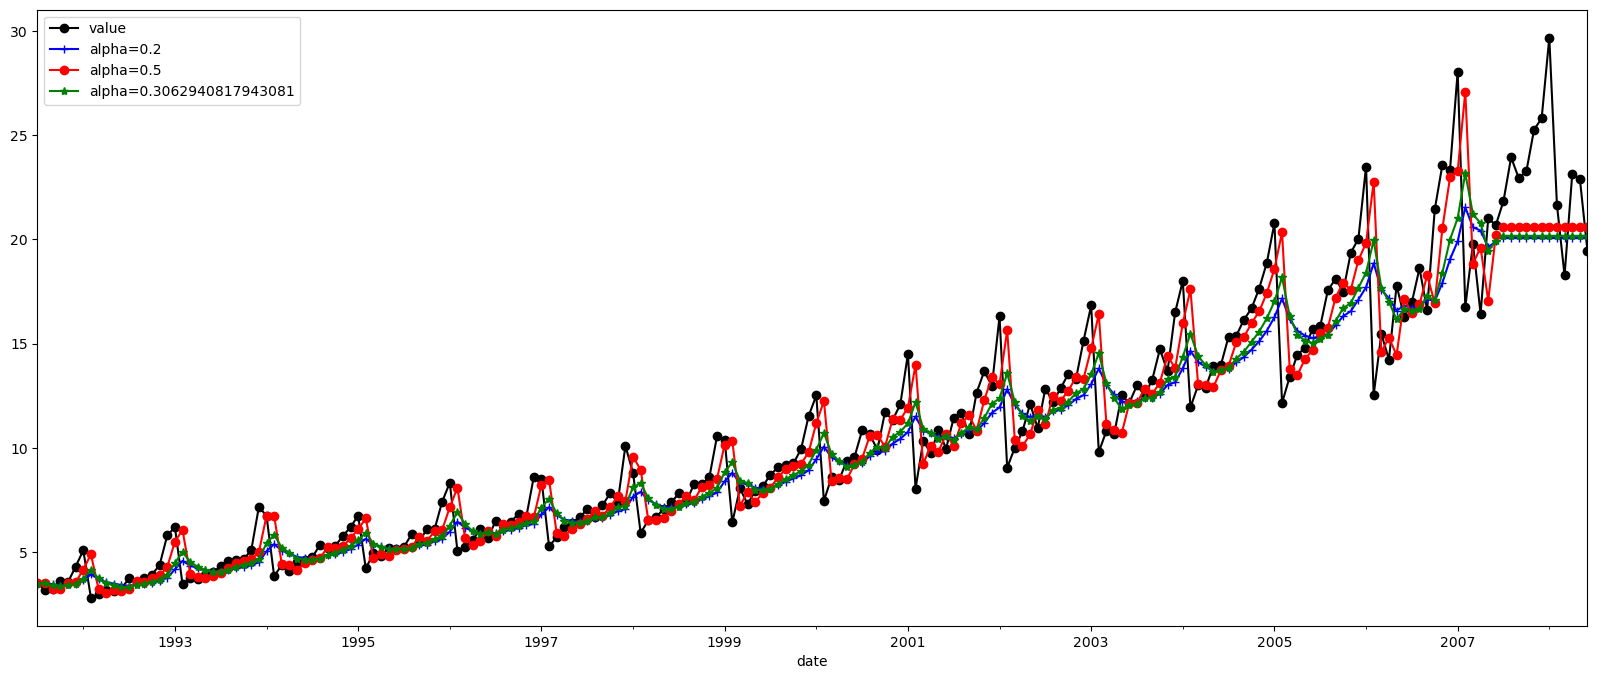

In [107]:
#After creating model we will visualize the plot
ax = dmed_4.plot(marker='o', color='black', figsize=(20,8), legend=True)

#Plot for alpha =0.2
ins_cast1.plot(marker='+', ax=ax, color='blue', legend=True)
ins1.fittedvalues.plot(marker='+', ax=ax, color='blue')

#Plot for alpha = 0.5
ins_cast2.plot(marker='o', ax=ax, color='red', legend=True)
ins2.fittedvalues.plot(marker='o', ax=ax, color='red')

#Plot for alpha=Optimized by statsmodel
ins_cast3.plot(marker='*', ax=ax, color='green', legend=True)
ins3.fittedvalues.plot(marker='*', ax=ax, color='green')

plt.show()

#### Double Exponential Smoothing 

In [108]:
double_ets_add = ExponentialSmoothing(train_data4, trend = 'add').fit()
double_ets_mul = ExponentialSmoothing(train_data4, trend = 'mul').fit()

double_ets_add_pred = double_ets_add.forecast(12)
double_ets_mul_pred = double_ets_mul.forecast(12)

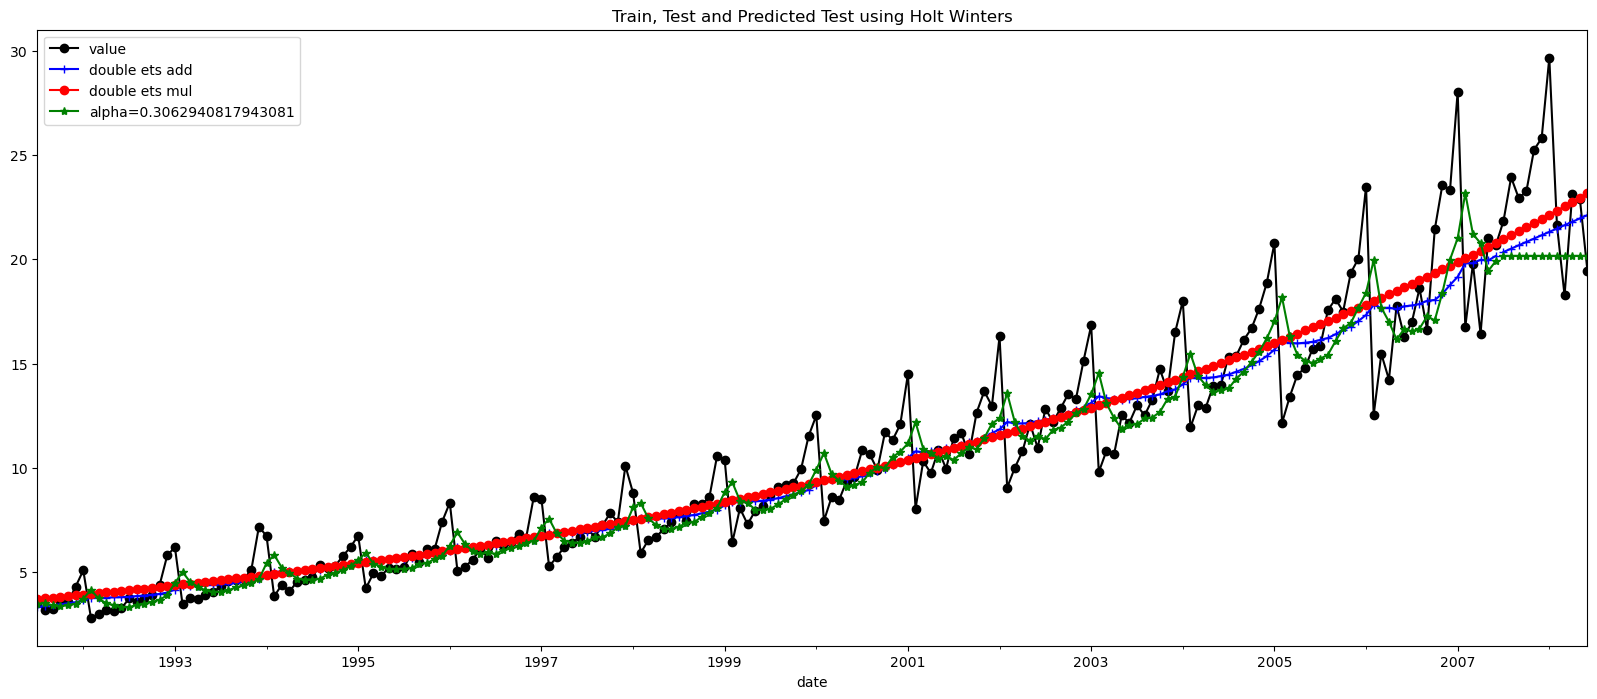

In [109]:
#plot the train, test, and predictions

#After creating model we will visualize the plot
ax = dmed_4.plot(marker='o', color='black', figsize=(20,8), legend=True)

#Plot for double ETS additive
double_ets_add_pred.plot(marker='+', ax=ax, color='blue', legend=True, label = 'double ets add')
double_ets_add.fittedvalues.plot(marker='+', ax=ax, color='blue')

#Plot for double ETS multiplicative
double_ets_mul_pred.plot(marker='o', ax=ax, color='red', legend=True, label = 'double ets mul')
double_ets_mul.fittedvalues.plot(marker='o', ax=ax, color='red')

#Plot for simple exponential smooting alpha=Optimized by statsmodel
ins_cast3.plot(marker='*', ax=ax, color='green', legend=True)
ins3.fittedvalues.plot(marker='*', ax=ax, color='green')
plt.title('Train, Test and Predicted Test using Holt Winters')
plt.show()

#### Triple Exponential Smoothing 

This is the extended version of simple exponential smoothing to allow the forecasting of data with a trend and seasonality.

In [110]:
# triple ETS - Holt Winter's Seasonal Method
triple_ets_add = ExponentialSmoothing(train_data4, trend = 'add', seasonal = 'add', seasonal_periods=12).fit()
triple_ets_mul = ExponentialSmoothing(train_data4, trend = 'mul', seasonal = 'mul', seasonal_periods=12).fit()

triple_ets_add_pred = triple_ets_add.forecast(12)
triple_ets_mul_pred = triple_ets_mul.forecast(12)

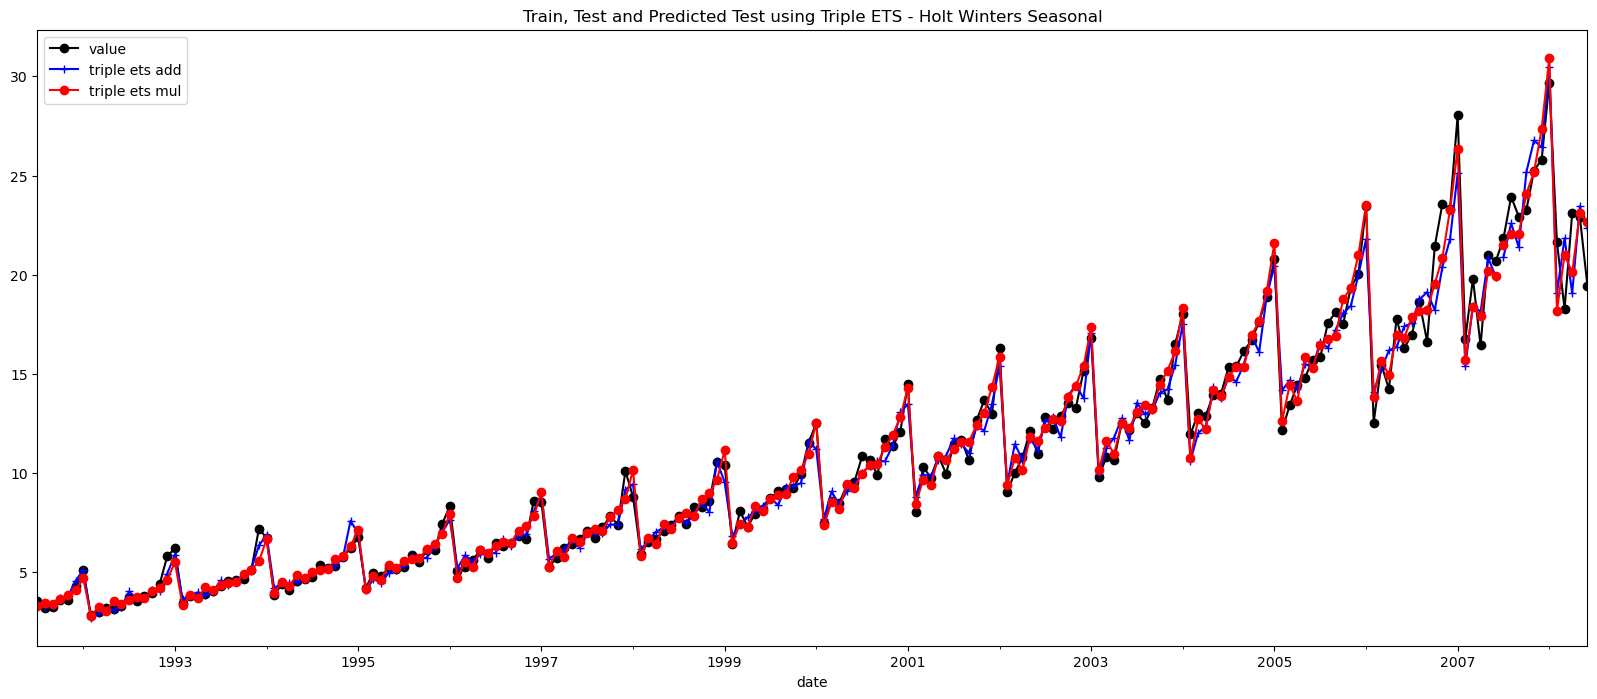

In [111]:
#plot the train, test, and predictions

#After creating model we will visualize the plot
ax = dmed_4.plot(marker='o', color='black', figsize=(20,8), legend=True)

#Plot for double ETS additive
triple_ets_add_pred.plot(marker='+', ax=ax, color='blue', legend=True, label = 'triple ets add')
triple_ets_add.fittedvalues.plot(marker='+', ax=ax, color='blue')

#Plot for double ETS multiplicative
triple_ets_mul_pred.plot(marker='o', ax=ax, color='red', legend=True, label = 'triple ets mul')
triple_ets_mul.fittedvalues.plot(marker='o', ax=ax, color='red')

plt.title('Train, Test and Predicted Test using Triple ETS - Holt Winters Seasonal')
plt.show()

#### Manual Arima

In [112]:
# p,d,q = 0,2,1 ARIMA Model
manual_model = sm.tsa.ARIMA(train_data4, order=(0,2,1))
manual_model_fit = manual_model.fit()
print(manual_model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                  value   No. Observations:                  192
Model:                 ARIMA(0, 2, 1)   Log Likelihood                -417.621
Date:                Fri, 18 Nov 2022   AIC                            839.242
Time:                        18:01:30   BIC                            845.736
Sample:                    07-01-1991   HQIC                           841.872
                         - 06-01-2007                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.9999      8.830     -0.113      0.910     -18.306      16.306
sigma2         4.6207     40.978      0.113      0.910     -75.694      84.936
Ljung-Box (L1) (Q):                  31.39   Jarque-

In [113]:
# Forecast
fc= manual_model_fit.forecast(12, alpha=0.05)  # 95% conf


In [114]:
conf= manual_model_fit.forecast(alpha=0.05)  # 95% conf


In [115]:
fc_series = pd.Series(fc, index=test_data4.index)
lower_series = pd.Series(conf, index=test_data4.index)
upper_series = pd.Series(conf, index=test_data4.index)


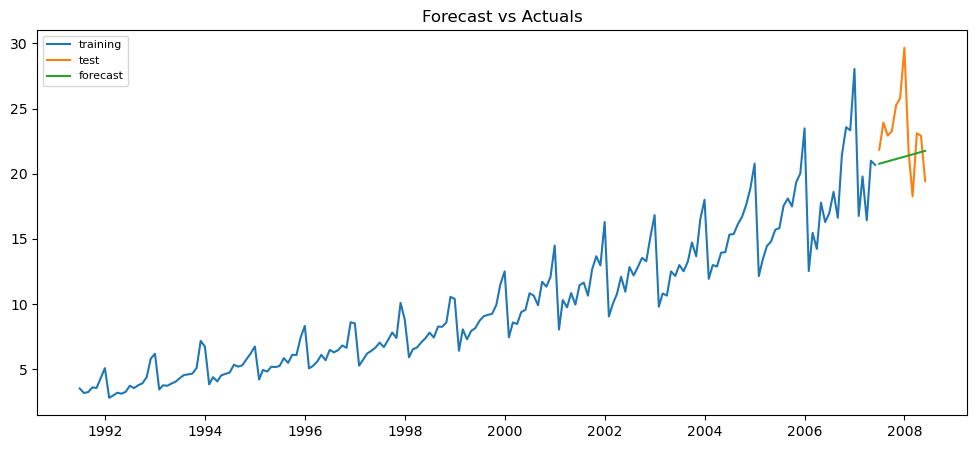

In [116]:
# Plot
plt.figure(figsize=(12,5), dpi=100)
plt.plot(train_data4, label='training')
plt.plot(test_data4, label='test')
plt.plot(fc_series, label='forecast')
plt.fill_between(lower_series.index, lower_series, upper_series, 
                 color='k', alpha=.15)
plt.title('Forecast vs Actuals')
plt.legend(loc='upper left', fontsize=8)
plt.show();


#### Auto ARIMA - Non Seasonal

In [117]:
non_seasonal_auto_model = pm.auto_arima(train_data4, start_p=0, start_q=0, 
                          test='adf',       # use adftest to find optimal 'd'
                          max_p=3, max_q=3, # maximum p and q
                          m=12,              # frequency of series
                          d=None,           # let model determine 'd'
                          seasonal=False,   # No Seasonality
                          trace=True,
                          error_action='ignore',  
                          suppress_warnings=True, 
                          stepwise=True)

print(non_seasonal_auto_model.summary())

Performing stepwise search to minimize aic
 ARIMA(0,0,0)(0,0,0)[0]             : AIC=1473.879, Time=0.02 sec
 ARIMA(1,0,0)(0,0,0)[0]             : AIC=844.283, Time=0.03 sec
 ARIMA(0,0,1)(0,0,0)[0]             : AIC=1279.130, Time=0.03 sec
 ARIMA(2,0,0)(0,0,0)[0]             : AIC=inf, Time=0.05 sec
 ARIMA(1,0,1)(0,0,0)[0]             : AIC=802.660, Time=0.06 sec
 ARIMA(2,0,1)(0,0,0)[0]             : AIC=794.855, Time=0.10 sec
 ARIMA(3,0,1)(0,0,0)[0]             : AIC=795.190, Time=0.15 sec
 ARIMA(2,0,2)(0,0,0)[0]             : AIC=799.333, Time=0.15 sec
 ARIMA(1,0,2)(0,0,0)[0]             : AIC=797.769, Time=0.08 sec
 ARIMA(3,0,0)(0,0,0)[0]             : AIC=inf, Time=0.06 sec
 ARIMA(3,0,2)(0,0,0)[0]             : AIC=785.896, Time=0.21 sec
 ARIMA(3,0,3)(0,0,0)[0]             : AIC=792.088, Time=0.35 sec
 ARIMA(2,0,3)(0,0,0)[0]             : AIC=788.158, Time=0.18 sec
 ARIMA(3,0,2)(0,0,0)[0] intercept   : AIC=788.803, Time=0.27 sec

Best model:  ARIMA(3,0,2)(0,0,0)[0]          
Total 

In [118]:
# Forecast
n_periods = 12
fc_auto_nonseasonal, confint = non_seasonal_auto_model.predict(n_periods=n_periods, return_conf_int=True)

In [119]:
fc_auto_nonseasonal

2007-07-01    21.107272
2007-08-01    19.519617
2007-09-01    20.670836
2007-10-01    19.354552
2007-11-01    20.595240
2007-12-01    19.320149
2008-01-01    20.566994
2008-02-01    19.302882
2008-03-01    20.544987
2008-04-01    19.287862
2008-05-01    20.523825
2008-06-01    19.273136
Freq: MS, dtype: float64

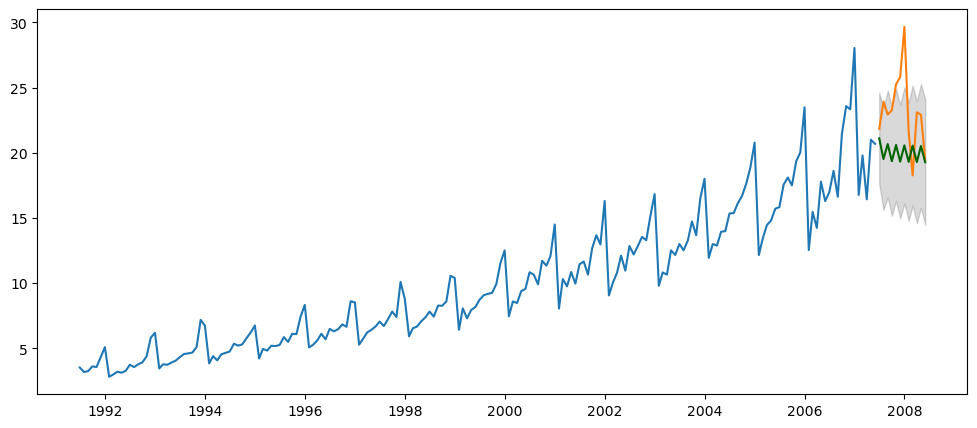

In [120]:
# make plot
fc_series_auto_nonseasonal = pd.Series(fc_auto_nonseasonal, index=test_data4.index)
lower_series = pd.Series(confint[:, 0], index=test_data4.index)
upper_series = pd.Series(confint[:, 1], index=test_data4.index)

# Plot
plt.figure(figsize=(12,5), dpi=100)
plt.plot(train_data4, label='train')
plt.plot(test_data4, label='test')
plt.plot(fc_series_auto_nonseasonal, color='darkgreen', label='forecast')
plt.fill_between(lower_series.index, 
                 lower_series, 
                 upper_series, 
                 color='k', alpha=.15)

plt.show()

#### Auto ARIMA Seasonal 

In [121]:
# Seasonal - fit stepwise auto-ARIMA
smodel = pm.auto_arima(train_data4, start_p=1, start_q=1,
                         test='adf',
                         max_p=3, max_q=3, m=12,
                         start_P=0, seasonal=True,
                         d=None, D=1, trace=True,
                         error_action='ignore',  
                         suppress_warnings=True, 
                         stepwise=True)

smodel.summary()

Performing stepwise search to minimize aic
 ARIMA(1,1,1)(0,1,1)[12]             : AIC=422.169, Time=0.15 sec
 ARIMA(0,1,0)(0,1,0)[12]             : AIC=505.309, Time=0.02 sec
 ARIMA(1,1,0)(1,1,0)[12]             : AIC=440.957, Time=0.07 sec
 ARIMA(0,1,1)(0,1,1)[12]             : AIC=422.766, Time=0.10 sec
 ARIMA(1,1,1)(0,1,0)[12]             : AIC=423.219, Time=0.05 sec
 ARIMA(1,1,1)(1,1,1)[12]             : AIC=423.200, Time=0.25 sec
 ARIMA(1,1,1)(0,1,2)[12]             : AIC=421.304, Time=0.44 sec
 ARIMA(1,1,1)(1,1,2)[12]             : AIC=420.235, Time=0.91 sec
 ARIMA(1,1,1)(2,1,2)[12]             : AIC=422.207, Time=1.04 sec
 ARIMA(1,1,1)(2,1,1)[12]             : AIC=420.588, Time=0.67 sec
 ARIMA(0,1,1)(1,1,2)[12]             : AIC=420.770, Time=0.61 sec
 ARIMA(1,1,0)(1,1,2)[12]             : AIC=435.856, Time=0.56 sec
 ARIMA(2,1,1)(1,1,2)[12]             : AIC=420.069, Time=1.02 sec
 ARIMA(2,1,1)(0,1,2)[12]             : AIC=420.743, Time=0.78 sec
 ARIMA(2,1,1)(1,1,1)[12]         

<class 'statsmodels.iolib.summary.Summary'>
"""
                                     SARIMAX Results                                      
==========================================================================================
Dep. Variable:                                  y   No. Observations:                  192
Model:             SARIMAX(3, 1, 2)x(1, 1, 2, 12)   Log Likelihood                -199.854
Date:                            Fri, 18 Nov 2022   AIC                            417.708
Time:                                    18:02:13   BIC                            446.395
Sample:                                07-01-1991   HQIC                           429.341
                                     - 06-01-2007                                         
Covariance Type:                              opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.5685      0.199     -2.853      0.004      -0.959      -0.178
ar.L2          0.3586      0.130      2.760      0.006       0.104       0.613
ar.L3          0.3405      0.077      4.416      0.000       0.189       0.492
ma.L1         -0.2247      0.231     -0.974      0.330      -0.677       0.227
ma.L2         -0.6161      0.171     -3.609      0.000      -0.951      -0.282
ar.S.L12      -0.5863      0.357     -1.643      0.100      -1.286       0.113
ma.S.L12       0.4531      0.353      1.284      0.199      -0.239       1.145
ma.S.L24      -0.2938      0.103     -2.852      0.004      -0.496      -0.092
sigma2         0.5347      0.042     12.711      0.000       0.452       0.617
===================================================================================
Ljung-Box (L1) (Q):                   0.02   Jarque-Bera (JB):               161.14
Prob(Q):                              0.89   Prob(JB):                         0.00
Heteroskedasticity (H):               8.91   Skew:                             0.57
Prob(H) (two-sided):                  0.00   Kurtosis:                         7.51
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [122]:
# Forecast
n_periods = 12
fc_auto_seasonal, confint = smodel.predict(n_periods=n_periods, return_conf_int=True)

In [123]:
fc_auto_seasonal

2007-07-01    20.320189
2007-08-01    22.168197
2007-09-01    20.120709
2007-10-01    24.361956
2007-11-01    26.282086
2007-12-01    26.089891
2008-01-01    30.348335
2008-02-01    19.278756
2008-03-01    22.159073
2008-04-01    19.445034
2008-05-01    23.176642
2008-06-01    23.319140
Freq: MS, dtype: float64

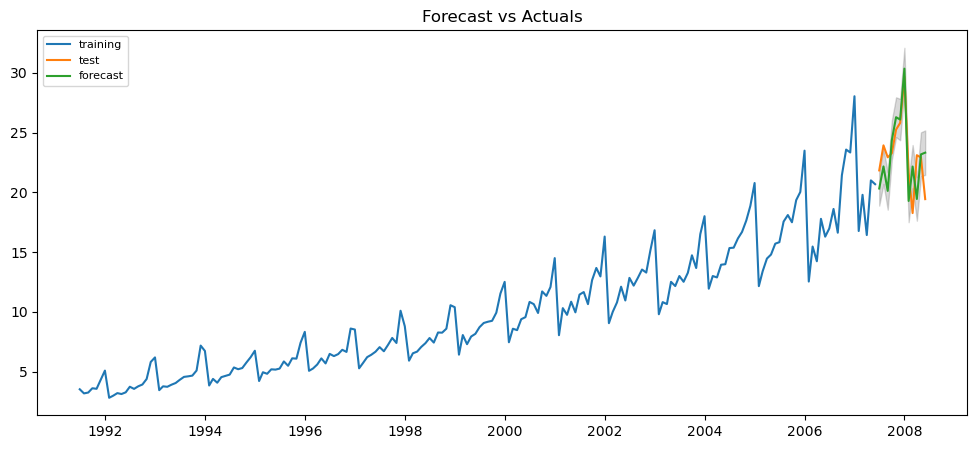

In [124]:
# make series for plotting purpose
fc_series_auto_seasonal = pd.Series(fc_auto_seasonal, index=test_data4.index)
lower_series = pd.Series(confint[:, 0], index=test_data4.index)
upper_series = pd.Series(confint[:, 1], index=test_data4.index)

# Plot
plt.figure(figsize=(12,5), dpi=100)
plt.plot(train_data4, label='training')
plt.plot(test_data4, label='test')
plt.plot(fc_series_auto_seasonal, label='forecast')
plt.fill_between(lower_series.index, lower_series, upper_series, 
                 color='k', alpha=.15)
plt.title('Forecast vs Actuals')
plt.legend(loc='upper left', fontsize=8)
plt.show()

#### Model Evaluation

In [125]:
#define metrics dataframe which will be used below for 
metrics_dataframe = pd.DataFrame(columns=['Model', 'RMSE', 'MAE', 'MAPE'])

                                 
def metrics_cal(actuals, predictions, model):
    mse = mean_squared_error(actuals, predictions)
    rmse = sqrt(mse)
    mae = mean_absolute_error(actuals, predictions)
    mape = np.mean(np.abs((actuals - predictions) / actuals)) * 100
    
    df = pd.DataFrame({'Model': model,
                       'RMSE': rmse,
                       'MAE': mae, 
                       'MAPE': mape}, index=[0])
    dataframe = metrics_dataframe.append(df)
    return dataframe

In [126]:
#get all the metrics
metrics_dataframe = metrics_cal(test_data4.values.flatten(), 
                                triple_ets_add_pred.values.flatten(), 
                                'Triple Add')

metrics_dataframe = metrics_cal(test_data4.values.flatten(), 
                                triple_ets_mul_pred.values.flatten(), 
                                'Triple Mul')

metrics_dataframe = metrics_cal(test_data4.values.flatten(), 
                                fc_series.values.flatten(), 
                                'Manual ARIMA')

metrics_dataframe = metrics_cal(test_data4.values.flatten(), 
                                fc_series_auto_nonseasonal.values.flatten(), 
                                'Auto ARIMA Non Seasonal')

metrics_dataframe = metrics_cal(test_data4.values.flatten(), 
                                fc_series_auto_seasonal.values.flatten(), 
                                'Auto ARIMA Seasonal')

In [127]:
metrics_dataframe.sort_values(by='MAE')

,Model,RMSE,MAE,MAPE
0,Triple Mul,1.998203,1.616775,7.383740
0,Triple Add,2.174516,1.863363,8.537842
0,Auto ARIMA Seasonal,2.336596,1.938970,9.005336
0,Manual ARIMA,3.500004,2.831393,11.749451
0,Auto ARIMA Non Seasonal,4.261564,3.545346,14.480975


In [128]:
# Create a data frame with all the predictions along with the test data
test_pred_df = test_data4.copy()

# Add all predictions 
test_pred_df = test_pred_df.assign(manual_arima_pred = fc_series.values.flatten(),
                                   auto_nonseasonal_pred = fc_series_auto_nonseasonal.values.flatten(),
                                   auto_seasonal_pred = fc_series_auto_seasonal.values.flatten(),
                                   avg_pred = (fc_series.values.flatten()+
                                               fc_series_auto_nonseasonal.values.flatten()+
                                               fc_series_auto_seasonal.values.flatten())/3)

test_pred_df

,value,manual_arima_pred,auto_nonseasonal_pred,auto_seasonal_pred,avg_pred
date,,,,,
2007-07-01,21.834890,20.770817,21.107272,20.320189,20.732759
2007-08-01,23.930204,20.860631,19.519617,22.168197,20.849482
2007-09-01,22.930357,20.950446,20.670836,20.120709,20.580663
2007-10-01,23.263340,21.040260,19.354552,24.361956,21.585589
2007-11-01,25.250030,21.130075,20.595240,26.282086,22.669133
2007-12-01,25.806090,21.219889,19.320149,26.089891,22.209976
2008-01-01,29.665356,21.309704,20.566994,30.348335,24.075011
2008-02-01,21.654285,21.399518,19.302882,19.278756,19.993719
2008-03-01,18.264945,21.489333,20.544987,22.159073,21.397797


In [129]:
metrics_dataframe = metrics_cal(test_data4.values.flatten(), 
                                test_pred_df['avg_pred'], 
                                'Average')

In [130]:
metrics_dataframe.sort_values(by='MAE')

,Model,RMSE,MAE,MAPE
0,Triple Mul,1.998203,1.616775,7.383740
0,Triple Add,2.174516,1.863363,8.537842
0,Auto ARIMA Seasonal,2.336596,1.938970,9.005336
0,Average,2.840422,2.576337,10.957427
0,Manual ARIMA,3.500004,2.831393,11.749451
0,Auto ARIMA Non Seasonal,4.261564,3.545346,14.480975


## Conclusion

For all 4 scenarios the Triple Mul model presented the best scores for RMSE MAE and MAPE
